# 抓杯子：从新采集到新权重的完整实训

本篇执行红杯单任务的完整实验：40 个固定种子采集 → 全部入库轨迹的物理回放 → 5000 次 ACT［动作分块变换器］训练更新 → 30 个新种子闭环评估。采集为脚本专家控制；评估只使用学习策略输出。

本篇的新实验与旧红蓝杯历史成绩分别展示。打开文件直接查看已保存输出；重新执行完整实验时设置 `AMD_RUN_FULL=1`，并给出下面的工程、解释器和外置结果路径。未开启执行开关时显示本次已保存证据。


## 环境、输入与输出

复用已安装的 ROCm［AMD异构计算平台］训练环境与匹配的旧版 LeRobot 代码。仿真资产取自原抓杯子工程的 `asset` 文件夹。结果目录独立保存数据、日志、新权重和视频；课程目录保存轻量结果快照。

| 参数 | 本篇配方 |
|---|---|
| 采集随机种子 | 1000–1039，共40次尝试，只保存物理成功演示 |
| 训练 | 5000次更新，批量8，梯度累积1，有效批量8，学习率0.0001 |
| 初始化 | 缓存的视觉骨干；动作变换器随机初始化；优化全部可训练参数 |
| 输入与输出 | 两路图像、末端位姿 → 六关节目标与夹爪命令 |
| 动作块 | 20步；控制频率20赫兹 |
| 评估 | 2000–2029，共30回合，每回合最多1200控制步 |
| 物理成功 | 至少抬升6厘米并保持3步，杯子放到盘上、松爪，最终直立余弦≥0.85 |

开始前至少保留12 GiB［二进制吉字节］磁盘空间。统一内存峰值由真实训练日志记录。脚本专家会读取物体位置用于采集；学习策略不读取物体真值，也不使用回放动作或专家纠正。


In [1]:
from pathlib import Path
import os, sys, json, subprocess
from IPython.display import display, Markdown, HTML, Image
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/cup_pipeline/course_run.py").is_file())
SOURCE = Path(os.environ.get("CUP_SOURCE_DIR", str(TOPIC / "code/cup_pipeline"))).resolve()
RUN_FULL = os.environ.get("AMD_RUN_FULL", "0") == "1"
RUN = Path(os.environ.get("CUP_RUN_ROOT", "/data/Data14TB/runs/every_embodied/cup-full-v1"))
SNAPSHOT = TOPIC / "notebooks/results/cup-full"
print({"完整执行": RUN_FULL, "源码": str(SOURCE), "实验目录": str(RUN)})
if RUN_FULL:
    for key in ("EXPERIMENT_PYTHON", "LEROBOT_SRC", "PNP_ASSET_ROOT"):
        assert os.environ.get(key), f"需要设置 {key}"
    assert Path(os.environ["EXPERIMENT_PYTHON"]).is_file()
def stage(name):
    if RUN_FULL:
        subprocess.run([os.environ["EXPERIMENT_PYTHON"], str(SOURCE / "course_run.py"), name], check=True)
    else:
        state_file = SNAPSHOT / "pipeline_state.json"
        state = json.loads(state_file.read_text()) if state_file.exists() else {"status": "等待本次实训完成"}
        display(Markdown("```json\n" + json.dumps(state.get("completed", {}).get(name, state), ensure_ascii=False, indent=2) + "\n```"))


{'完整执行': False, '源码': '/home/ubuntu/Documents/具身教程编写/every-embodied-amd/16-专题组队学习/04-AMD-ROCm策略复刻专题/code/cup_pipeline', '实验目录': '/data/Data14TB/runs/every_embodied/cup-full-v1'}


## 1. 新采集与入库

依次执行40个种子，保存每次尝试的结果及录像。至少20条物理成功演示入库才进入下一阶段；失败尝试保留在采集记录中。

### 采集：专家动作、轨迹与图像存储

以下单元直接展开本阶段真实源码。启用完整运行时，入口使用笔记本中定义的函数，并沿用数据、物理成功条件及恢复检查。

In [2]:
if RUN_FULL:
    from pathlib import Path
    import sys
    assert Path(sys.executable).resolve() == Path(os.environ["EXPERIMENT_PYTHON"]).resolve(), "Select the configured experiment kernel."
    sys.path.insert(0, str(SOURCE))
    sys.path.insert(0, os.environ["LEROBOT_SRC"])
    __file__ = str(SOURCE / 'collect_pnp_scripted_oracle.py')


In [3]:
if RUN_FULL:
    """Scripted oracle collection for randomized red-mug pick-and-place.

    The script first drives the environment with end-effector delta commands, then
    stores the resulting joint-angle actions in the same format as the teleop
    collector. This keeps generated episodes replayable by the existing ACT data
    audit and training code.
    """

    import argparse

    import json

    import os

    import shutil

    import time

    from pathlib import Path

    from types import SimpleNamespace

    import cv2

    import numpy as np

    from PIL import Image

    os.environ.setdefault("SUCCESS_REQUIRE_EE_HEIGHT", "0")

    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

    TASK_NAME = "Pick up the red mug and place it on the white plate."

    def parse_args() -> argparse.Namespace:
        parser = argparse.ArgumentParser()
        parser.add_argument("--seeds", default="1013,1017,1022,1024")
        parser.add_argument("--seed-start", type=int, default=None)
        parser.add_argument("--num-demos", type=int, default=None)
        parser.add_argument(
            "--root",
            type=Path,
            default=Path("/data/Data14TB/datasets/every_embodied/omy_pnp_scripted_oracle_v0"),
        )
        parser.add_argument("--repo-id", default="datawhale_eai_pnp_scripted_oracle")
        parser.add_argument(
            "--video-dir",
            type=Path,
            default=Path("/data/Data14TB/videos/every_embodied/pnp_scripted_oracle_v0"),
        )
        parser.add_argument("--write-dataset", action="store_true")
        parser.add_argument("--overwrite", action="store_true")
        parser.add_argument("--resume", action="store_true")
        parser.add_argument("--save-failed", action="store_true")
        parser.add_argument("--task", default=TASK_NAME)
        parser.add_argument("--fps", type=int, default=20)
        parser.add_argument("--video-fps", type=float, default=20.0)
        parser.add_argument("--frame-every", type=int, default=2)
        parser.add_argument("--width", type=int, default=960)
        parser.add_argument("--height", type=int, default=720)
        parser.add_argument(
            "--physics-steps-per-action",
            type=int,
            default=25,
            help="MuJoCo substeps per recorded control action; 25 matches 500Hz physics / 20Hz control.",
        )
        parser.add_argument("--move-step", type=float, default=0.004)
        parser.add_argument(
            "--record-action-source",
            choices=["commanded", "observed"],
            default="commanded",
            help="Store commanded IK joints or observed joint state as the supervised action.",
        )
        parser.add_argument("--place-step-scale", type=float, default=0.65)
        parser.add_argument("--pos-tol", type=float, default=0.008)
        parser.add_argument("--max-move-steps", type=int, default=260)
        parser.add_argument("--max-total-actions", type=int, default=900)
        parser.add_argument("--initial-hold", type=int, default=12)
        parser.add_argument("--close-hold", type=int, default=64)
        parser.add_argument("--pre-release-hold", type=int, default=12)
        parser.add_argument("--open-hold", type=int, default=70)
        parser.add_argument("--final-hold", type=int, default=35)
        parser.add_argument("--success-hold-frames", type=int, default=6)
        parser.add_argument("--grasp-offset-x", type=float, default=0.006)
        parser.add_argument("--grasp-offset-y", type=float, default=0.086)
        parser.add_argument("--grasp-offset-z", type=float, default=0.026)
        parser.add_argument("--pregrasp-z", type=float, default=0.135)
        parser.add_argument("--lift-z", type=float, default=0.145)
        parser.add_argument("--release-offset-x", type=float, default=0.008)
        parser.add_argument("--release-offset-y", type=float, default=0.026)
        parser.add_argument("--release-offset-z", type=float, default=0.095)
        parser.add_argument("--retreat-z", type=float, default=0.145)
        parser.add_argument("--physical-min-lift", type=float, default=0.06)
        parser.add_argument("--physical-min-lift-steps", type=int, default=3)
        parser.add_argument("--physical-final-upright-cos", type=float, default=0.85)
        parser.add_argument(
            "--policy-prefix-path",
            type=Path,
            default=None,
            help="Optional ACT checkpoint. If set, roll this policy for --policy-prefix-steps before scripted recovery.",
        )
        parser.add_argument("--policy-prefix-repo-id", default=None)
        parser.add_argument("--policy-prefix-dataset-root", type=Path, default=None)
        parser.add_argument("--policy-prefix-device", default="cuda")
        parser.add_argument("--policy-prefix-act-n-action-steps", type=int, default=None)
        parser.add_argument("--policy-prefix-act-clamp-timestamp", action="store_true")
        parser.add_argument(
            "--policy-prefix-act-episode-timestamp-offsets",
            default="",
            help="Episode timestamp offsets used by the ACT prefix checkpoint, e.g. '49-71:2.0'.",
        )
        parser.add_argument(
            "--policy-prefix-act-episode-source-flags",
            default="",
            help="Episode source flags used by the ACT prefix checkpoint, e.g. '49-71:1.0'.",
        )
        parser.add_argument("--policy-prefix-steps", type=int, default=0)
        parser.add_argument("--policy-prefix-hz", type=float, default=20.0)
        parser.add_argument("--policy-prefix-task", default="Put mug cup on the plate")
        return parser.parse_args()

    def parse_seeds(args: argparse.Namespace) -> list[int]:
        if args.seed_start is not None and args.num_demos is not None:
            return [int(args.seed_start + i) for i in range(args.num_demos)]
        seeds: list[int] = []
        for part in str(args.seeds).split(","):
            part = part.strip()
            if part:
                seeds.append(int(part))
        if args.num_demos is not None:
            seeds = seeds[: int(args.num_demos)]
        if not seeds:
            raise ValueError("No seeds requested")
        return seeds

    def dataset_features() -> dict:
        return {
            "observation.image": {
                "dtype": "image",
                "shape": (256, 256, 3),
                "names": ["height", "width", "channels"],
            },
            "observation.wrist_image": {
                "dtype": "image",
                "shape": (256, 256, 3),
                "names": ["height", "width", "channel"],
            },
            "observation.state": {
                "dtype": "float32",
                "shape": (6,),
                "names": ["state"],
            },
            "action": {
                "dtype": "float32",
                "shape": (7,),
                "names": ["action"],
            },
            "obj_init": {
                "dtype": "float32",
                "shape": (6,),
                "names": ["obj_init"],
            },
        }


In [4]:
if RUN_FULL:
    def make_dataset(args: argparse.Namespace):
        if not args.write_dataset:
            return None
        from lerobot.common.datasets.lerobot_dataset import LeRobotDataset

        if args.root.exists() and args.overwrite:
            shutil.rmtree(args.root)
        if args.root.exists() and not args.resume:
            raise SystemExit(f"Dataset root exists. Use --resume or --overwrite: {args.root}")
        if args.root.exists():
            return LeRobotDataset(args.repo_id, root=args.root)
        return LeRobotDataset.create(
            repo_id=args.repo_id,
            root=args.root,
            robot_type="omy",
            fps=args.fps,
            features=dataset_features(),
            image_writer_threads=10,
            image_writer_processes=5,
        )

    def resize_rgb(image: np.ndarray) -> np.ndarray:
        return np.asarray(Image.fromarray(image).resize((256, 256)))

    def round_list(values, ndigits: int = 4) -> list[float]:
        return [round(float(x), ndigits) for x in np.asarray(values).reshape(-1)]

    def make_writer(path: Path, args: argparse.Namespace):
        path.parent.mkdir(parents=True, exist_ok=True)
        writer = cv2.VideoWriter(
            str(path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            float(args.video_fps),
            (int(args.width), int(args.height)),
        )
        if not writer.isOpened():
            raise RuntimeError(f"Failed to open video writer: {path}")
        return writer

    def draw_overlay(frame: np.ndarray, seed: int, action_step: int, phase: str, debug: dict) -> np.ndarray:
        out = frame.copy()
        physical_success = bool(debug.get("physical_success", False))
        lines = [
            f"scripted oracle seed={seed} | step {action_step} | {phase}",
            (
                f"success={bool(debug.get('success', False))} "
                f"physical_success={physical_success} "
                f"lift={float(debug.get('max_mug_lift', 0.0)):.3f} "
                f"upright={float(debug.get('final_mug_upright_cos', 0.0)):.3f}"
            ),
            (
                f"xy={float(debug.get('xy_dist', 0.0)):.3f} "
                f"z={float(debug.get('z_dist', 0.0)):.3f} "
                f"ee_z={float(debug.get('ee_z', 0.0)):.3f} "
                f"grip_open={float(debug.get('gripper_open_norm', 0.0)):.3f}"
            ),
        ]
        pad = 10
        line_h = 28
        cv2.rectangle(out, (0, 0), (out.shape[1], pad * 2 + line_h * len(lines)), (0, 0, 0), -1)
        color = (130, 255, 130) if physical_success else (255, 255, 255)
        for idx, line in enumerate(lines):
            cv2.putText(
                out,
                line,
                (pad, pad + 20 + idx * line_h),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.64,
                color,
                2,
                cv2.LINE_AA,
            )
        return out

    def write_video_frame(writer, image: np.ndarray, seed: int, step: int, phase: str, debug: dict, args: argparse.Namespace) -> None:
        frame = cv2.resize(np.asarray(image), (args.width, args.height), interpolation=cv2.INTER_AREA)
        frame = draw_overlay(frame, seed, step, phase, debug)
        writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))

    def clip_delta(delta: np.ndarray, step: float) -> np.ndarray:
        return np.clip(delta, -float(step), float(step)).astype(np.float32)

    def target_positions(env, args: argparse.Namespace) -> dict[str, np.ndarray]:
        mug, plate = env.get_obj_pose()
        mug = np.asarray(mug, dtype=np.float32)
        plate = np.asarray(plate, dtype=np.float32)
        grasp = mug + np.array([args.grasp_offset_x, args.grasp_offset_y, args.grasp_offset_z], dtype=np.float32)
        pregrasp = grasp.copy()
        pregrasp[2] = mug[2] + float(args.pregrasp_z)
        lift = grasp.copy()
        lift[2] = mug[2] + float(args.lift_z)
        preplace = plate + np.array([args.release_offset_x, args.release_offset_y, args.lift_z], dtype=np.float32)
        release = plate + np.array([args.release_offset_x, args.release_offset_y, args.release_offset_z], dtype=np.float32)
        retreat = release.copy()
        retreat[2] = plate[2] + float(args.retreat_z)
        return {
            "mug": mug,
            "plate": plate,
            "pregrasp": pregrasp,
            "grasp": grasp,
            "lift": lift,
            "preplace": preplace,
            "release": release,
            "retreat": retreat,
        }


In [5]:
if RUN_FULL:
    def control_tick(
        env,
        dataset,
        writer,
        seed: int,
        phase: str,
        action: np.ndarray,
        state: dict,
        args: argparse.Namespace,
    ):
        from eval_policy_success import get_act_physical_debug, update_act_physical_tracker

        for _ in range(max(int(args.physics_steps_per_action), 1)):
            env.step_env()
            state["sim_steps"] += 1
            update_act_physical_tracker(env, state["tracker"], state["physical_args"])
        debug = env.get_success_debug() if hasattr(env, "get_success_debug") else {"success": bool(env.check_success())}
        debug = get_act_physical_debug(env, state["tracker"], state["physical_args"], debug)
        state["last_debug"] = debug
        if env.check_success():
            state["success_hold"] += 1
        else:
            state["success_hold"] = 0
        if debug["physical_success"]:
            state["physical_success_ever"] = True
            if state["first_physical_success_step"] is None:
                state["first_physical_success_step"] = state["action_steps"]

        ee_pose = env.get_ee_pose()
        agent_image, wrist_image = env.grab_image()
        if writer is not None and (state["action_steps"] % max(int(args.frame_every), 1) == 0):
            write_video_frame(writer, agent_image, seed, state["action_steps"], phase, debug, args)
            state["video_frames"] += 1

        joint_q = np.asarray(env.step(action), dtype=np.float32)
        if args.record_action_source == "commanded":
            arm_q = np.asarray(getattr(env, "compute_q", joint_q[:-1]), dtype=np.float32).reshape(-1)
            if arm_q.shape[0] != 6:
                raise ValueError(f"Expected 6-D commanded arm action, got shape {arm_q.shape}")
            recorded_action = np.concatenate([arm_q, np.asarray([float(action[-1])], dtype=np.float32)])
        else:
            if joint_q.shape[0] != 7:
                raise ValueError(f"Expected 7-D observed action, got shape {joint_q.shape}")
            recorded_action = joint_q.copy()
        recorded_action[-1] = float(action[-1])
        state["actions"].append(recorded_action.copy())
        state["phases"].append(phase)

        if dataset is not None:
            dataset.add_frame(
                {
                    "observation.image": resize_rgb(agent_image),
                    "observation.wrist_image": resize_rgb(wrist_image),
                    "observation.state": np.asarray(ee_pose, dtype=np.float32),
                    "action": recorded_action,
                    "obj_init": np.asarray(env.obj_init_pose, dtype=np.float32),
                },
                task=args.task,
            )

        state["action_steps"] += 1
        if state["action_steps"] > args.max_total_actions:
            raise RuntimeError(f"Exceeded --max-total-actions={args.max_total_actions}")

    def hold(env, dataset, writer, seed: int, phase: str, gripper: float, steps: int, state: dict, args: argparse.Namespace) -> None:
        action = np.zeros(7, dtype=np.float32)
        action[-1] = float(gripper)
        for _ in range(max(int(steps), 0)):
            control_tick(env, dataset, writer, seed, phase, action, state, args)

    def move_to(
        env,
        dataset,
        writer,
        seed: int,
        phase: str,
        target: np.ndarray,
        gripper: float,
        state: dict,
        args: argparse.Namespace,
        step_scale: float = 1.0,
    ) -> None:
        target = np.asarray(target, dtype=np.float32)
        for _ in range(int(args.max_move_steps)):
            current = np.asarray(env.get_ee_pose()[:3], dtype=np.float32)
            delta = target - current
            if float(np.linalg.norm(delta)) <= float(args.pos_tol):
                return
            action = np.zeros(7, dtype=np.float32)
            action[:3] = clip_delta(delta, float(args.move_step) * float(step_scale))
            action[-1] = float(gripper)
            control_tick(env, dataset, writer, seed, phase, action, state, args)
        raise RuntimeError(f"Failed to reach target for phase={phase}: target={round_list(target)}")

    def make_policy_prefix(args: argparse.Namespace):
        if args.policy_prefix_path is None or int(args.policy_prefix_steps) <= 0:
            return None
        if args.policy_prefix_repo_id is None:
            raise ValueError("--policy-prefix-repo-id is required when --policy-prefix-path is set")
        if args.policy_prefix_dataset_root is None:
            raise ValueError("--policy-prefix-dataset-root is required when --policy-prefix-path is set")
        import torch
        from eval_policy_success import make_act_policy

        if args.policy_prefix_device == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("Policy prefix requested cuda, but torch.cuda.is_available() is false")
        policy = make_act_policy(
            args.policy_prefix_device,
            args.policy_prefix_path,
            args.policy_prefix_repo_id,
            args.policy_prefix_dataset_root,
            n_action_steps=args.policy_prefix_act_n_action_steps,
            episode_timestamp_offsets=args.policy_prefix_act_episode_timestamp_offsets,
            episode_source_flags=args.policy_prefix_act_episode_source_flags,
        )
        policy.clamp_timestamp_to_dataset = bool(args.policy_prefix_act_clamp_timestamp)
        return policy


In [6]:
if RUN_FULL:
    def run_policy_prefix(env, policy, seed: int, args: argparse.Namespace) -> dict:
        """Roll ACT into its own visited state, then hand control back to eef oracle."""
        import torch
        from eval_policy_success import get_act_state, make_timestamp_env_feature, to_tensor_image

        if policy is None or int(args.policy_prefix_steps) <= 0:
            return {"enabled": False, "steps": 0}

        old_action_type = env.action_type
        env.action_type = "joint_angle"
        policy.reset()
        rows: list[dict] = []
        try:
            for action_step in range(int(args.policy_prefix_steps)):
                for _ in range(max(int(args.physics_steps_per_action), 1)):
                    env.step_env()
                batch = {
                    "task": [args.policy_prefix_task],
                    "timestamp": torch.tensor(
                        [action_step / float(args.policy_prefix_hz)],
                        dtype=torch.float32,
                        device=args.policy_prefix_device,
                    ),
                }
                state = None
                if "observation.state" in policy.config.input_features:
                    state = get_act_state(env, policy, action_step, float(args.policy_prefix_hz))
                    batch["observation.state"] = torch.tensor(
                        np.asarray([state]), dtype=torch.float32, device=args.policy_prefix_device
                    )
                if "observation.environment_state" in policy.config.input_features:
                    env_state = make_timestamp_env_feature(
                        action_step / float(args.policy_prefix_hz),
                        getattr(policy, "timestamp_env_max_timestamp", action_step / float(args.policy_prefix_hz)),
                        getattr(policy, "timestamp_env_frequencies", 0),
                    )
                    batch["observation.environment_state"] = torch.tensor(
                        env_state[None, :], dtype=torch.float32, device=args.policy_prefix_device
                    )
                if "observation.state" not in batch:
                    batch["observation.state"] = torch.zeros((1, 1), dtype=torch.float32, device=args.policy_prefix_device)
                if policy.config.image_features:
                    image, wrist_image = env.grab_image()
                    if "observation.image" in policy.config.input_features:
                        batch["observation.image"] = to_tensor_image(image).unsqueeze(0).to(args.policy_prefix_device)
                    if "observation.wrist_image" in policy.config.input_features:
                        batch["observation.wrist_image"] = to_tensor_image(wrist_image).unsqueeze(0).to(args.policy_prefix_device)
                with torch.no_grad():
                    action = policy.select_action(batch)[0].detach().cpu().numpy().astype(np.float32)
                env.step(action)
                if action_step < 5 or action_step == int(args.policy_prefix_steps) - 1:
                    rows.append(
                        {
                            "step": int(action_step),
                            "action": round_list(action),
                            "tcp_pos": round_list(env.env.get_p_body(env.ee_body_name)),
                            "mug_pos": round_list(env.env.get_p_body("body_obj_mug_5")),
                            "state": round_list(state) if state is not None else None,
                        }
                    )
        finally:
            env.action_type = old_action_type
            env.p0, env.R0 = env.env.get_pR_body(body_name=env.ee_body_name)

        return {
            "enabled": True,
            "policy_path": str(args.policy_prefix_path),
            "steps": int(args.policy_prefix_steps),
            "act_clamp_timestamp": bool(args.policy_prefix_act_clamp_timestamp),
            "act_episode_timestamp_offsets": args.policy_prefix_act_episode_timestamp_offsets,
            "act_episode_source_flags": args.policy_prefix_act_episode_source_flags,
            "sampled_steps": rows,
            "final_tcp_pos": round_list(env.env.get_p_body(env.ee_body_name)),
            "final_mug_pos": round_list(env.env.get_p_body("body_obj_mug_5")),
        }

    def run_episode(env, dataset, seed: int, args: argparse.Namespace, policy_prefix=None) -> dict:
        from eval_policy_success import get_act_physical_debug, init_act_physical_tracker

        env.reset(seed=seed)
        prefix_info = run_policy_prefix(env, policy_prefix, seed, args)
        points = target_positions(env, args)
        physical_args = SimpleNamespace(
            physical_min_lift=args.physical_min_lift,
            physical_min_lift_steps=args.physical_min_lift_steps,
            physical_final_upright_cos=args.physical_final_upright_cos,
        )
        tracker = init_act_physical_tracker(env)
        debug = env.get_success_debug() if hasattr(env, "get_success_debug") else {"success": bool(env.check_success())}
        debug = get_act_physical_debug(env, tracker, physical_args, debug)
        state = {
            "tracker": tracker,
            "physical_args": physical_args,
            "action_steps": 0,
            "sim_steps": 0,
            "video_frames": 0,
            "success_hold": 0,
            "physical_success_ever": False,
            "first_physical_success_step": None,
            "last_debug": debug,
            "actions": [],
            "phases": [],
        }

        args.video_dir.mkdir(parents=True, exist_ok=True)
        mp4_path = args.video_dir / f"scripted_oracle_seed{seed}.mp4"
        writer = make_writer(mp4_path, args)
        try:
            hold(env, dataset, writer, seed, "initial_open_hold", 0.0, args.initial_hold, state, args)
            move_to(env, dataset, writer, seed, "move_pregrasp", points["pregrasp"], 0.0, state, args)
            move_to(env, dataset, writer, seed, "move_grasp", points["grasp"], 0.0, state, args)
            hold(env, dataset, writer, seed, "close_gripper", 1.0, args.close_hold, state, args)
            move_to(env, dataset, writer, seed, "lift_mug", points["lift"], 1.0, state, args)
            move_to(env, dataset, writer, seed, "move_preplace", points["preplace"], 1.0, state, args)
            move_to(
                env,
                dataset,
                writer,
                seed,
                "lower_to_plate",
                points["release"],
                1.0,
                state,
                args,
                step_scale=args.place_step_scale,
            )
            hold(env, dataset, writer, seed, "pre_release_hold", 1.0, args.pre_release_hold, state, args)
            hold(env, dataset, writer, seed, "open_gripper", 0.0, args.open_hold, state, args)
            move_to(env, dataset, writer, seed, "retreat", points["retreat"], 0.0, state, args)
            hold(env, dataset, writer, seed, "final_open_hold", 0.0, args.final_hold, state, args)
        finally:
            writer.release()

        actions = np.stack(state["actions"]).astype(np.float32) if state["actions"] else np.zeros((0, 7), dtype=np.float32)
        npz_path = args.video_dir / f"scripted_oracle_seed{seed}_actions.npz"
        np.savez_compressed(npz_path, recorded=actions, phases=np.asarray(state["phases"], dtype=object))
        debug = state["last_debug"]
        physical_success = bool(state["physical_success_ever"] or debug.get("physical_success", False))
        success = bool(env.check_success() or debug.get("success", False))
        row = {
            "seed": seed,
            "success": success,
            "physical_success": physical_success,
            "action_steps": int(state["action_steps"]),
            "sim_steps": int(state["sim_steps"]),
            "video_frames": int(state["video_frames"]),
            "first_physical_success_step": state["first_physical_success_step"],
            "obj_init": round_list(env.obj_init_pose),
            "targets": {key: round_list(value) for key, value in points.items()},
            "policy_prefix": prefix_info,
            "debug": debug,
            "video": str(mp4_path),
            "actions_npz": str(npz_path),
            "record_action_source": args.record_action_source,
        }
        return row

    def episode_count(root: Path) -> int:
        path = root / "meta" / "episodes.jsonl"
        if not path.exists():
            return 0
        return sum(1 for line in path.read_text(encoding="utf-8").splitlines() if line.strip())


In [7]:
if RUN_FULL:
    def main() -> int:
        from mujoco_env.y_env import SimpleEnv

        args = parse_args()
        seeds = parse_seeds(args)
        dataset = make_dataset(args)
        manifest_path = args.root / "collection_manifest.jsonl"
        if args.write_dataset:
            args.root.mkdir(parents=True, exist_ok=True)
        args.video_dir.mkdir(parents=True, exist_ok=True)
        summary_path = args.video_dir / "scripted_oracle_summary.jsonl"
        if summary_path.exists() and args.overwrite:
            summary_path.unlink()

        env = SimpleEnv("./asset/example_scene_y.xml", action_type="eef_pose")
        policy_prefix = make_policy_prefix(args)
        rows: list[dict] = []
        try:
            for seed in seeds:
                started_episode_count = episode_count(args.root) if args.write_dataset else None
                start = time.time()
                try:
                    row = run_episode(env, dataset, seed, args, policy_prefix=policy_prefix)
                    row["elapsed_s"] = round(time.time() - start, 3)
                    save_episode = bool(args.write_dataset and (row["physical_success"] or args.save_failed))
                    row["dataset_saved"] = save_episode
                    if save_episode:
                        dataset.save_episode()
                        row["episode_index"] = started_episode_count
                        with manifest_path.open("a", encoding="utf-8") as f:
                            f.write(
                                json.dumps(
                                    {
                                        "saved_at": time.strftime("%Y-%m-%d %H:%M:%S"),
                                        "episode_in_run": started_episode_count,
                                        "seed": seed,
                                        "frames": row["action_steps"],
                                        "obj_init": row["obj_init"],
                                        "success_debug": row["debug"],
                                        "source": "scripted_oracle",
                                        "video": row["video"],
                                        "actions_npz": row["actions_npz"],
                                    },
                                    ensure_ascii=False,
                                )
                                + "\n"
                            )
                    elif dataset is not None:
                        dataset.clear_episode_buffer()
                    rows.append(row)
                    with summary_path.open("a", encoding="utf-8") as f:
                        f.write(json.dumps(row, ensure_ascii=False) + "\n")
                    print(json.dumps(row, ensure_ascii=False), flush=True)
                except Exception as exc:
                    if dataset is not None:
                        dataset.clear_episode_buffer()
                    row = {
                        "seed": seed,
                        "error": repr(exc),
                        "physical_success": False,
                        "dataset_saved": False,
                        "elapsed_s": round(time.time() - start, 3),
                    }
                    rows.append(row)
                    with summary_path.open("a", encoding="utf-8") as f:
                        f.write(json.dumps(row, ensure_ascii=False) + "\n")
                    print(json.dumps(row, ensure_ascii=False), flush=True)

        finally:
            try:
                env.env.close_viewer()
            except Exception:
                pass

        summary = {
            "seeds": seeds,
            "episodes": len(rows),
            "physical_success_count": sum(1 for row in rows if row.get("physical_success", False)),
            "dataset_saved_count": sum(1 for row in rows if row.get("dataset_saved", False)),
            "root": str(args.root),
            "video_dir": str(args.video_dir),
            "summary_jsonl": str(summary_path),
        }
        summary_json = args.video_dir / "scripted_oracle_summary.json"
        summary_json.write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
        print("SUMMARY " + json.dumps(summary, ensure_ascii=False), flush=True)
        return 0


In [8]:
if RUN_FULL:
    import hashlib
    assert hashlib.sha256((SOURCE / 'collect_pnp_scripted_oracle.py').read_bytes()).hexdigest() == "10d00039b90eb4dc0f2d89cc028e7cf10d83634e419c67212b04800b590c4cbc", "Notebook/source stage versions differ"
    import importlib.util
    _stage_spec = importlib.util.spec_from_file_location("notebook_stage_coordinator", SOURCE / "course_run.py")
    _stage_coordinator = importlib.util.module_from_spec(_stage_spec)
    _stage_spec.loader.exec_module(_stage_coordinator)
    def _execute_inline_stage(argv):
        previous = sys.argv[:]
        try:
            sys.argv = list(argv)
            return main()
        finally:
            sys.argv = previous
    _stage_coordinator.run('collect', stage_callable=_execute_inline_stage)
else:
    stage('collect')


```json
{
  "attempts": 40,
  "saved_episodes": 40,
  "frames": 15195
}
```

## 2. 全数据回放

在相同随机种子下回放每条入库演示的关节目标，检查采集动作与部署动作的一致性。全部通过后开始训练。

### 回放：逐条演示复核

以下单元直接展开本阶段真实源码。启用完整运行时，入口使用笔记本中定义的函数，并沿用数据、物理成功条件及恢复检查。

In [9]:
if RUN_FULL:
    from pathlib import Path
    import sys
    assert Path(sys.executable).resolve() == Path(os.environ["EXPERIMENT_PYTHON"]).resolve(), "Select the configured experiment kernel."
    sys.path.insert(0, str(SOURCE))
    sys.path.insert(0, os.environ["LEROBOT_SRC"])
    __file__ = str(SOURCE / 'audit_pnp_dataset_physical.py')


In [10]:
if RUN_FULL:
    """Per-episode physical replay audit for the randomized PnP LeRobot dataset."""

    import argparse

    import json

    import os

    import time

    from pathlib import Path

    import numpy as np

    import pandas as pd

    os.environ.setdefault("SUCCESS_REQUIRE_EE_HEIGHT", "0")

    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

    def parse_args() -> argparse.Namespace:
        parser = argparse.ArgumentParser()
        parser.add_argument("--repo-id", default="datawhale_eai_pnp")
        parser.add_argument("--root", type=Path, required=True)
        parser.add_argument("--hz", type=float, default=20.0)
        parser.add_argument("--settle-actions", type=int, default=20)
        parser.add_argument("--episodes", default="all", help="all or comma-separated episode indexes")
        parser.add_argument("--output-jsonl", type=Path, required=True)
        parser.add_argument("--summary-json", type=Path, required=True)
        parser.add_argument("--physical-min-lift", type=float, default=0.06)
        parser.add_argument("--physical-min-lift-steps", type=int, default=3)
        parser.add_argument("--physical-final-upright-cos", type=float, default=0.85)
        return parser.parse_args()

    def load_manifest(root: Path) -> dict[int, dict]:
        path = root / "collection_manifest.jsonl"
        if not path.exists():
            return {}
        rows = {}
        for line in path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            row = json.loads(line)
            rows[int(row["episode_in_run"])] = row
        return rows

    def parse_episode_indexes(spec: str, total: int) -> list[int]:
        if spec.strip().lower() == "all":
            return list(range(total))
        indexes = []
        for part in spec.split(","):
            part = part.strip()
            if not part:
                continue
            indexes.append(int(part))
        return indexes

    def load_episode_lengths(root: Path) -> list[int]:
        path = root / "meta" / "episodes.jsonl"
        lengths: list[int] = []
        for line in path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            row = json.loads(line)
            lengths.append(int(row["length"]))
        return lengths

    def episode_path(root: Path, episode_index: int) -> Path:
        info = json.loads((root / "meta" / "info.json").read_text(encoding="utf-8"))
        chunk_size = int(info.get("chunks_size", 1000))
        episode_chunk = episode_index // chunk_size
        rel = info.get(
            "data_path",
            "data/chunk-{episode_chunk:03d}/episode_{episode_index:06d}.parquet",
        ).format(episode_chunk=episode_chunk, episode_index=episode_index)
        return root / rel

    def load_episode_actions(root: Path, episode_index: int) -> np.ndarray:
        df = pd.read_parquet(episode_path(root, episode_index), columns=["action"])
        return np.stack([np.asarray(action, dtype=np.float32) for action in df["action"].tolist()])

    def replay_episode(actions: np.ndarray, env, episode_index: int, seed: int | None, args: argparse.Namespace) -> dict:
        from eval_policy_success import (
            get_act_physical_debug,
            init_act_physical_tracker,
            update_act_physical_tracker,
        )

        length = int(actions.shape[0])
        total_actions = length + max(args.settle_actions, 0)
        env.reset(seed=seed)

        tracker = init_act_physical_tracker(env)
        action_steps = 0
        sim_steps = 0
        success_ever = False
        first_success_step = None
        physical_success_ever = False
        first_physical_success_step = None
        last_debug = {}
        last_action = actions[0]

        start_time = time.time()
        while action_steps < total_actions and env.env.is_viewer_alive():
            env.step_env()
            sim_steps += 1
            if not env.env.loop_every(HZ=args.hz):
                continue

            if action_steps < length:
                action = actions[action_steps]
                last_action = action
                phase = "dataset"
            else:
                action = last_action
                phase = "settle"

            env.step(action)
            update_act_physical_tracker(env, tracker, args)
            if hasattr(env, "get_success_debug"):
                last_debug = env.get_success_debug()
            else:
                last_debug = {"success": bool(env.check_success())}
            last_debug = get_act_physical_debug(env, tracker, args, last_debug)

            if env.check_success():
                success_ever = True
                if first_success_step is None:
                    first_success_step = action_steps
            if last_debug["physical_success"]:
                physical_success_ever = True
                if first_physical_success_step is None:
                    first_physical_success_step = action_steps

            action_steps += 1

        if hasattr(env, "get_success_debug"):
            last_debug = env.get_success_debug()
        else:
            last_debug = {"success": bool(env.check_success())}
        last_debug = get_act_physical_debug(env, tracker, args, last_debug)
        physical_success = bool(physical_success_ever or last_debug["physical_success"])
        success = bool(success_ever or env.check_success())
        last_debug.update(
            {
                "legacy_success_ever": success,
                "first_legacy_success_step": first_success_step,
                "physical_success_ever": physical_success,
                "first_physical_success_step": first_physical_success_step,
            }
        )
        return {
            "episode_index": episode_index,
            "seed": seed,
            "dataset_length": length,
            "settle_actions": max(args.settle_actions, 0),
            "action_steps": action_steps,
            "sim_steps": sim_steps,
            "elapsed_s": round(time.time() - start_time, 3),
            "last_phase": phase if action_steps else None,
            "success": success,
            "physical_success": physical_success,
            "debug": last_debug,
        }


In [11]:
if RUN_FULL:
    def main() -> int:
        from mujoco_env.y_env import SimpleEnv

        args = parse_args()
        args.output_jsonl.parent.mkdir(parents=True, exist_ok=True)
        args.summary_json.parent.mkdir(parents=True, exist_ok=True)
        if args.output_jsonl.exists():
            args.output_jsonl.unlink()

        episode_lengths = load_episode_lengths(args.root)
        manifest = load_manifest(args.root)
        indexes = parse_episode_indexes(args.episodes, len(episode_lengths))
        env = SimpleEnv("./asset/example_scene_y.xml", action_type="joint_angle")

        rows = []
        try:
            for episode_index in indexes:
                manifest_row = manifest.get(episode_index, {})
                seed = manifest_row.get("seed")
                actions = load_episode_actions(args.root, episode_index)
                row = replay_episode(actions, env, episode_index, seed, args)
                row["manifest"] = {
                    "seed": seed,
                    "frames": manifest_row.get("frames"),
                    "obj_init": manifest_row.get("obj_init"),
                }
                rows.append(row)
                with args.output_jsonl.open("a", encoding="utf-8") as f:
                    f.write(json.dumps(row, ensure_ascii=False) + "\n")
                print(json.dumps(row, ensure_ascii=False), flush=True)
        finally:
            try:
                env.env.close_viewer()
            except Exception:
                pass

        summary = {
            "repo_id": args.repo_id,
            "root": str(args.root),
            "episodes": len(rows),
            "legacy_success_count": sum(1 for row in rows if row["success"]),
            "physical_success_count": sum(1 for row in rows if row["physical_success"]),
            "legacy_success_rate": sum(1 for row in rows if row["success"]) / max(len(rows), 1),
            "physical_success_rate": sum(1 for row in rows if row["physical_success"]) / max(len(rows), 1),
            "episode_indexes": indexes,
            "physical_min_lift": args.physical_min_lift,
            "physical_min_lift_steps": args.physical_min_lift_steps,
            "physical_final_upright_cos": args.physical_final_upright_cos,
        }
        args.summary_json.write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
        print("SUMMARY " + json.dumps(summary, ensure_ascii=False), flush=True)
        return 0


In [12]:
if RUN_FULL:
    import hashlib
    assert hashlib.sha256((SOURCE / 'audit_pnp_dataset_physical.py').read_bytes()).hexdigest() == "2e7754b7bcbf1a18b525b3518535474b527c3693d38422e50c95ba5cea83514b", "Notebook/source stage versions differ"
    import importlib.util
    _stage_spec = importlib.util.spec_from_file_location("notebook_stage_coordinator", SOURCE / "course_run.py")
    _stage_coordinator = importlib.util.module_from_spec(_stage_spec)
    _stage_spec.loader.exec_module(_stage_coordinator)
    def _execute_inline_stage(argv):
        previous = sys.argv[:]
        try:
            sys.argv = list(argv)
            return main()
        finally:
            sys.argv = previous
    _stage_coordinator.run('audit', stage_callable=_execute_inline_stage)
else:
    stage('audit')


```json
{
  "repo_id": "amd_cup_red_v1",
  "root": "/home/aup/amd-notebook-work/cup-full-20261027-v1/dataset",
  "episodes": 40,
  "legacy_success_count": 40,
  "physical_success_count": 40,
  "legacy_success_rate": 1.0,
  "physical_success_rate": 1.0,
  "episode_indexes": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39
  ],
  "physical_min_lift": 0.06,
  "physical_min_lift_steps": 3,
  "physical_final_upright_cos": 0.85
}
```

## 3. 完整训练

执行5000次真实梯度更新，记录损失、耗时、设备、实际可训练参数和内存峰值。遇到非有限损失立即停止并保存日志；最终保存新权重及内容指纹。

## 笔记本内的实际训练实现

依次阅读图像解码与增强、轨迹采样、动作块与归一化、模型构造、损失计算以及完整参数更新循环。代码与本篇配方的训练源码保持对应；默认展示已有结果，完整运行时使用以下单元定义的训练函数。

In [13]:
if RUN_FULL:
    import sys
    from pathlib import Path
    assert Path(sys.executable).resolve() == Path(os.environ["EXPERIMENT_PYTHON"]).resolve(), "Select the configured training kernel before running."
    sys.path.insert(0, os.environ["LEROBOT_SRC"])
    sys.path.insert(0, str(SOURCE))


### 数据、模型与训练循环

下面是实际源码展开后的代码单元，包含数据、模型、损失、梯度更新和保存逻辑；完整运行开关打开时在当前笔记本内执行。来源：`code/cup_pipeline/train_act_chunk.py`；SHA256［256位安全散列］：`d9ed02b4567fc426fe91941be867032c9dae2d786be21fbc781cc7eff8a603ff`。

In [14]:
if RUN_FULL:
    """Train ACT with a configurable action chunk and print chunk diagnostics."""

    import argparse

    from copy import deepcopy

    import io

    import json

    import math

    import os

    import time

    from itertools import cycle

    from pathlib import Path

    import numpy as np

    import torch

    import torch.nn.functional as F

    import torchvision.transforms as T

    from PIL import Image

    from torchvision import transforms

    def patch_lerobot_image_transform() -> None:
        """Handle parquet image rows decoded as dict payloads on some platforms."""
        import lerobot.common.datasets.lerobot_dataset as ds_mod
        import lerobot.common.datasets.utils as ds_utils

        def hf_transform_to_torch_patched(items_dict):
            to_tensor = T.ToTensor()
            for key in items_dict:
                first_item = items_dict[key][0]
                if isinstance(first_item, Image.Image):
                    items_dict[key] = [to_tensor(img) for img in items_dict[key]]
                elif isinstance(first_item, dict) and ("bytes" in first_item or "path" in first_item):
                    out = []
                    for item in items_dict[key]:
                        if isinstance(item, dict) and item.get("bytes") is not None:
                            img = Image.open(io.BytesIO(item["bytes"])).convert("RGB")
                            out.append(to_tensor(img))
                        else:
                            out.append(item)
                    items_dict[key] = out
                elif first_item is None:
                    pass
                else:
                    items_dict[key] = [
                        item if isinstance(item, str) else torch.tensor(item) for item in items_dict[key]
                    ]
            return items_dict

        ds_utils.hf_transform_to_torch = hf_transform_to_torch_patched
        ds_mod.hf_transform_to_torch = hf_transform_to_torch_patched

    class AddGaussianNoise:
        def __init__(self, mean: float = 0.0, std: float = 0.02):
            self.mean = mean
            self.std = std

        def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
            return tensor + torch.randn(tensor.size()) * self.std + self.mean

    class Clamp01:
        def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
            return tensor.clamp(0, 1)

    def tensor_to_device_batch(batch: dict, device: torch.device) -> dict:
        return {key: (value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value) for key, value in batch.items()}

    def _action_array(action: torch.Tensor) -> np.ndarray:
        if isinstance(action, torch.Tensor):
            return action.detach().cpu().numpy()
        return np.asarray(action)

    def _first_action_vector(action: torch.Tensor) -> np.ndarray:
        action_np = _action_array(action)
        if action_np.ndim == 2:
            return action_np[0]
        return action_np

    def _action_motion_norm(action: torch.Tensor) -> float:
        action_np = _action_array(action)
        if action_np.ndim == 2 and action_np.shape[0] > 1:
            return float(np.linalg.norm(action_np[-1, :6] - action_np[0, :6]))
        return 0.0

    def _base_dataset_object(dataset):
        base = dataset
        while hasattr(base, "dataset"):
            base = base.dataset
        return base

    def _base_hf_dataset(dataset):
        base = _base_dataset_object(dataset)
        return getattr(base, "hf_dataset", None)

    def _hf_column(dataset, name: str):
        base = _base_dataset_object(dataset)
        hf_dataset = getattr(base, "hf_dataset", None)
        if hf_dataset is None:
            return None
        cache = getattr(base, "_codex_hf_column_cache", None)
        if cache is None:
            cache = {}
            setattr(base, "_codex_hf_column_cache", cache)
        if name not in cache:
            cache[name] = hf_dataset[name]
        return cache[name]

    def _has_timestamp_offsets(dataset) -> bool:
        base = dataset
        while True:
            if getattr(base, "timestamp_offsets", None):
                return True
            if not hasattr(base, "dataset"):
                return False
            base = base.dataset

    def _timestamp_offsets(dataset) -> dict[int, float]:
        base = dataset
        while True:
            offsets = getattr(base, "timestamp_offsets", None)
            if offsets:
                return {int(k): float(v) for k, v in offsets.items()}
            if not hasattr(base, "dataset"):
                return {}
            base = base.dataset

    def _raw_dataset_index(dataset, idx: int) -> int:
        if hasattr(dataset, "indices"):
            idx = int(dataset.indices[int(idx)])
        if hasattr(dataset, "dataset"):
            return _raw_dataset_index(dataset.dataset, idx)
        return int(idx)

    def _raw_first_action_vector(dataset, idx: int) -> np.ndarray:
        hf_dataset = _base_hf_dataset(dataset)
        if hf_dataset is not None:
            return np.asarray(_hf_column(dataset, "action")[_raw_dataset_index(dataset, idx)], dtype=np.float32)
        return _first_action_vector(dataset[idx]["action"])

    def _episode_ranges(dataset) -> list[tuple[int, int, int]]:
        hf_dataset = _base_hf_dataset(dataset)
        episode_column = _hf_column(dataset, "episode_index") if hf_dataset is not None and "episode_index" in hf_dataset.column_names else None
        episode_ids: list[int] = []
        for idx in range(len(dataset)):
            if episode_column is not None:
                episode_ids.append(int(episode_column[_raw_dataset_index(dataset, idx)]))
                continue
            item = dataset[idx]
            if "episode_index" in item:
                episode_ids.append(int(item["episode_index"]))
            else:
                episode_ids.append(0)

        if not episode_ids:
            return []
        ranges: list[tuple[int, int, int]] = []
        start = 0
        current = episode_ids[0]
        for idx, episode_id in enumerate(episode_ids[1:], start=1):
            if episode_id != current:
                ranges.append((start, idx, current))
                start = idx
                current = episode_id
        ranges.append((start, len(episode_ids), current))
        return ranges


In [15]:
if RUN_FULL:
    def make_sampler(dataset, args: argparse.Namespace):
        if args.sample_mode == "uniform":
            return None

        weights = np.ones(len(dataset), dtype=np.float64)
        sampler_debug = {}
        episode_sample_weights = parse_episode_float_map(
            getattr(args, "episode_sample_weights", ""),
            "--episode-sample-weights",
        )
        if episode_sample_weights:
            episode_ranges = _episode_ranges(dataset)
            weighted_frames = 0
            matched_episodes: list[int] = []
            for start, end, episode_id in episode_ranges:
                factor = float(episode_sample_weights.get(int(episode_id), 1.0))
                if int(episode_id) in episode_sample_weights:
                    matched_episodes.append(int(episode_id))
                    weighted_frames += end - start
                weights[start:end] *= max(factor, 1e-9)
            sampler_debug.update(
                {
                    "episode_sample_weights": episode_sample_weights,
                    "episode_sample_weight_matched": matched_episodes,
                    "episode_sample_weighted_frames": int(weighted_frames),
                }
            )
        if args.sample_mode in ("early", "early-motion", "trajectory"):
            n = max(args.early_frame_count, 0)
            if args.per_episode_early and n > 0:
                early_weighted = 0
                episode_ranges = _episode_ranges(dataset)
                for start, end, _episode_id in episode_ranges:
                    hi = min(start + n, end)
                    if hi > start:
                        weights[start:hi] *= max(args.early_frame_weight, 1e-6)
                        early_weighted += hi - start
                sampler_debug.update(
                    {
                        "per_episode_early": True,
                        "episode_count": int(len(episode_ranges)),
                        "early_weighted_frames": int(early_weighted),
                    }
                )
            else:
                n = min(n, len(weights))
                weights[:n] *= max(args.early_frame_weight, 1e-6)
                sampler_debug.update({"per_episode_early": False, "early_weighted_frames": int(n)})

        if args.sample_mode in ("motion", "early-motion"):
            motions = np.zeros(len(dataset), dtype=np.float64)
            for idx in range(len(dataset)):
                if _base_hf_dataset(dataset) is not None:
                    if idx > 0:
                        motions[idx] = float(
                            np.linalg.norm(
                                _raw_first_action_vector(dataset, idx)[:6]
                                - _raw_first_action_vector(dataset, idx - 1)[:6]
                            )
                        )
                else:
                    motions[idx] = _action_motion_norm(dataset[idx]["action"])
            scale = float(np.percentile(motions, 95)) if np.any(motions > 0) else 0.0
            if scale > 1e-9:
                weights *= 1.0 + args.motion_frame_weight * np.clip(motions / scale, 0.0, 1.0)

        if args.sample_mode == "trajectory":
            actions = np.stack([_raw_first_action_vector(dataset, idx) for idx in range(len(dataset))])
            gripper = actions[:, 6]
            closed_mask = gripper > 0.5
            weights[closed_mask] *= max(args.gripper_closed_weight, 1e-6)

            transitions = np.flatnonzero(np.abs(np.diff(gripper, prepend=gripper[0])) > args.gripper_transition_threshold)
            window = max(args.gripper_transition_window, 0)
            for transition_idx in transitions:
                lo = max(int(transition_idx) - window, 0)
                hi = min(int(transition_idx) + window + 1, len(weights))
                weights[lo:hi] *= max(args.gripper_transition_weight, 1e-6)
            tail_count = min(max(args.tail_frame_count, 0), len(weights))
            if tail_count:
                weights[-tail_count:] *= max(args.tail_frame_weight, 1e-6)

            one_step_motion = np.zeros(len(dataset), dtype=np.float64)
            if len(dataset) > 1:
                one_step_motion[1:] = np.linalg.norm(actions[1:, :6] - actions[:-1, :6], axis=1)
            scale = float(np.percentile(one_step_motion, 95)) if np.any(one_step_motion > 0) else 0.0
            if scale > 1e-9:
                weights *= 1.0 + args.motion_frame_weight * np.clip(one_step_motion / scale, 0.0, 1.0)

            sampler_debug.update(
                {
                    "gripper_closed_frames": int(closed_mask.sum()),
                    "gripper_transition_count": int(len(transitions)),
                    "gripper_transition_indexes": [int(x) for x in transitions],
                    "gripper_closed_weight": args.gripper_closed_weight,
                    "gripper_transition_weight": args.gripper_transition_weight,
                    "gripper_transition_window": args.gripper_transition_window,
                    "tail_frame_count": args.tail_frame_count,
                    "tail_frame_weight": args.tail_frame_weight,
                }
            )

        weights = np.clip(weights, 1e-9, None)
        sampler = torch.utils.data.WeightedRandomSampler(
            weights=torch.as_tensor(weights, dtype=torch.double),
            num_samples=len(weights),
            replacement=True,
        )
        print(
            json.dumps(
                {
                    "event": "sampler",
                    "sample_mode": args.sample_mode,
                    "weight_min": round(float(weights.min()), 4),
                    "weight_max": round(float(weights.max()), 4),
                    "weight_mean": round(float(weights.mean()), 4),
                    "early_frame_count": args.early_frame_count,
                    "early_frame_weight": args.early_frame_weight,
                    "motion_frame_weight": args.motion_frame_weight,
                    **sampler_debug,
                },
                ensure_ascii=False,
            ),
            flush=True,
        )
        return sampler

    class TimestampStateDataset(torch.utils.data.Dataset):
        """Append the scalar LeRobot timestamp to observation.state."""

        def __init__(self, dataset):
            self.dataset = dataset

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[idx])
            state = item["observation.state"]
            timestamp = item["timestamp"]
            if not isinstance(timestamp, torch.Tensor):
                timestamp = torch.tensor(timestamp)
            timestamp = timestamp.reshape(1).to(dtype=state.dtype)
            item["observation.state"] = torch.cat([state, timestamp])
            return item


In [16]:
if RUN_FULL:
    class EpisodeSubsetDataset(torch.utils.data.Dataset):
        """Index into a subset of LeRobot episodes without copying parquet data."""

        def __init__(self, dataset, episode_indexes: list[int]):
            self.dataset = dataset
            self.episode_indexes = episode_indexes
            self.indices: list[int] = []
            for episode_index in episode_indexes:
                start = int(dataset.episode_data_index["from"][episode_index].item())
                end = int(dataset.episode_data_index["to"][episode_index].item())
                self.indices.extend(range(start, end))
            if not self.indices:
                raise ValueError(f"No frames selected by episode indexes: {episode_indexes}")

        def __len__(self) -> int:
            return len(self.indices)

        def __getitem__(self, idx: int) -> dict:
            return self.dataset[self.indices[int(idx)]]

    class EpisodeTimestampOffsetDataset(torch.utils.data.Dataset):
        """Add a timestamp offset for selected episodes without copying parquet data."""

        def __init__(self, dataset, timestamp_offsets: dict[int, float]):
            self.dataset = dataset
            self.timestamp_offsets = {int(k): float(v) for k, v in timestamp_offsets.items() if abs(float(v)) > 1e-9}

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[int(idx)])
            episode_index = item.get("episode_index")
            if isinstance(episode_index, torch.Tensor):
                episode_index = int(episode_index.detach().cpu().reshape(-1)[0])
            elif episode_index is not None:
                episode_index = int(episode_index)
            offset = self.timestamp_offsets.get(episode_index, 0.0)
            if offset:
                timestamp = item["timestamp"]
                if isinstance(timestamp, torch.Tensor):
                    item["timestamp"] = timestamp + timestamp.new_tensor(offset)
                else:
                    item["timestamp"] = np.asarray(timestamp, dtype=np.float32) + np.float32(offset)
            return item

    class EpisodeSourceFlagDataset(torch.utils.data.Dataset):
        """Append a per-episode source/correction flag to observation.state."""

        def __init__(self, dataset, source_flags: dict[int, float]):
            self.dataset = dataset
            self.source_flags = {int(k): float(v) for k, v in source_flags.items()}

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[int(idx)])
            state = item["observation.state"]
            episode_index = item.get("episode_index")
            if isinstance(episode_index, torch.Tensor):
                episode_index = int(episode_index.detach().cpu().reshape(-1)[0])
            elif episode_index is not None:
                episode_index = int(episode_index)
            flag = self.source_flags.get(episode_index, 0.0)
            flag_tensor = torch.as_tensor([flag], dtype=state.dtype, device=state.device)
            item["observation.state"] = torch.cat([state, flag_tensor])
            return item

    class TimestampOnlyStateDataset(torch.utils.data.Dataset):
        """Use only the scalar LeRobot timestamp as observation.state."""

        def __init__(self, dataset):
            self.dataset = dataset

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[idx])
            state = item["observation.state"]
            timestamp = item["timestamp"]
            if not isinstance(timestamp, torch.Tensor):
                timestamp = torch.tensor(timestamp)
            item["observation.state"] = timestamp.reshape(1).to(dtype=state.dtype)
            return item

    def _timestamp_float(timestamp) -> float:
        if isinstance(timestamp, torch.Tensor):
            return float(timestamp.detach().cpu().reshape(-1)[0])
        return float(np.asarray(timestamp).reshape(-1)[0])

    def make_timestamp_env_feature(timestamp, max_timestamp: float, frequencies: int) -> np.ndarray:
        ts = _timestamp_float(timestamp)
        if frequencies <= 0:
            return np.asarray([ts], dtype=np.float32)
        phase = np.clip(ts / max(max_timestamp, 1e-6), 0.0, 1.0)
        values = [phase]
        for k in range(1, frequencies + 1):
            angle = 2.0 * math.pi * k * phase
            values.extend([math.sin(angle), math.cos(angle)])
        return np.asarray(values, dtype=np.float32)

    class TimestampEnvStateDataset(torch.utils.data.Dataset):
        """Use the scalar LeRobot timestamp as observation.environment_state."""

        def __init__(self, dataset, max_timestamp: float, frequencies: int):
            self.dataset = dataset
            self.max_timestamp = max_timestamp
            self.frequencies = frequencies

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[idx])
            state = item["observation.state"]
            timestamp = item["timestamp"]
            env_state = make_timestamp_env_feature(timestamp, self.max_timestamp, self.frequencies)
            item["observation.environment_state"] = torch.as_tensor(env_state, dtype=state.dtype)
            item.pop("observation.image", None)
            item.pop("observation.wrist_image", None)
            return item

    class ObjInitStateDataset(torch.utils.data.Dataset):
        """Append mug/plate initial pose to observation.state."""

        def __init__(self, dataset):
            self.dataset = dataset

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[idx])
            state = item["observation.state"]
            obj_init = item["obj_init"]
            if not isinstance(obj_init, torch.Tensor):
                obj_init = torch.tensor(obj_init)
            item["observation.state"] = torch.cat([state, obj_init.reshape(-1).to(dtype=state.dtype)])
            return item

    class BinarizeGripperActionDataset(torch.utils.data.Dataset):
        """Replace the gripper target with a hard open/closed label."""

        def __init__(self, dataset, threshold: float):
            self.dataset = dataset
            self.threshold = threshold

        def __len__(self) -> int:
            return len(self.dataset)

        def __getitem__(self, idx: int) -> dict:
            item = dict(self.dataset[idx])
            action = item["action"].clone()
            action[..., 6] = (action[..., 6] > self.threshold).to(dtype=action.dtype)
            item["action"] = action
            return item


In [17]:
if RUN_FULL:
    def _timestamp_stats_from_values(values: np.ndarray, template: dict) -> dict:
        values = np.asarray(values, dtype=np.float32).reshape(-1)
        if values.size == 0:
            raise ValueError("Cannot compute timestamp stats from an empty dataset")
        out = {}
        for key in template:
            if key == "min":
                value = values.min()
            elif key == "max":
                value = values.max()
            elif key == "mean":
                value = values.mean()
            elif key == "std":
                value = values.std()
            elif key == "count":
                value = values.size
            else:
                value = np.asarray(template[key]).reshape(-1)[0]
            out[key] = np.asarray([value], dtype=np.float32)
        return out

    def append_timestamp_state_stats(stats: dict, timestamps: np.ndarray | None = None) -> dict:
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        timestamp_stats = patched["timestamp"]
        if timestamps is not None:
            timestamp_stats = _timestamp_stats_from_values(timestamps, timestamp_stats)
        for key in ("min", "max", "mean", "std"):
            state_stats[key] = np.concatenate([state_stats[key], timestamp_stats[key].reshape(1)])
        state_stats["std"][-1] = max(float(state_stats["std"][-1]), 1e-6)
        return patched

    def append_obj_init_state_stats(stats: dict) -> dict:
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        obj_stats = patched["obj_init"]
        for key in ("min", "max", "mean", "std"):
            state_stats[key] = np.concatenate([state_stats[key], np.asarray(obj_stats[key]).reshape(-1)])
        state_stats["std"] = np.maximum(state_stats["std"], 1e-6)
        return patched

    def append_episode_source_flag_state_stats(stats: dict, values: np.ndarray) -> dict:
        values = np.asarray(values, dtype=np.float32).reshape(-1)
        if values.size == 0:
            raise ValueError("Cannot compute source flag stats from an empty dataset")
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        for key in ("min", "max", "mean", "std"):
            if key == "min":
                value = values.min()
            elif key == "max":
                value = values.max()
            elif key == "mean":
                value = values.mean()
            else:
                value = max(float(values.std()), 1e-6)
            state_stats[key] = np.concatenate([state_stats[key], np.asarray([value], dtype=np.float32)])
        state_stats["std"][-1] = max(float(state_stats["std"][-1]), 1e-6)
        return patched

    def timestamp_only_state_stats(stats: dict) -> dict:
        patched = deepcopy(stats)
        timestamp_stats = patched["timestamp"]
        patched["observation.state"] = {}
        for key in ("min", "max", "mean", "std"):
            patched["observation.state"][key] = np.asarray(timestamp_stats[key], dtype=np.float32).reshape(1)
        patched["observation.state"]["std"][0] = max(float(patched["observation.state"]["std"][0]), 1e-6)
        return patched

    def timestamp_env_state_stats(
        stats: dict,
        timestamps: np.ndarray | None = None,
        max_timestamp: float | None = None,
        frequencies: int = 0,
    ) -> dict:
        patched = deepcopy(stats)
        if frequencies <= 0:
            timestamp_stats = patched["timestamp"]
            patched["observation.environment_state"] = {}
            for key in ("min", "max", "mean", "std"):
                patched["observation.environment_state"][key] = np.asarray(timestamp_stats[key], dtype=np.float32).reshape(1)
            patched["observation.environment_state"]["std"][0] = max(
                float(patched["observation.environment_state"]["std"][0]), 1e-6
            )
            return patched

        if timestamps is None or max_timestamp is None:
            raise ValueError("timestamps and max_timestamp are required when timestamp env frequencies are enabled")
        features = np.stack(
            [make_timestamp_env_feature(timestamp, max_timestamp, frequencies) for timestamp in timestamps]
        ).astype(np.float32)
        patched["observation.environment_state"] = {}
        for key in ("min", "max", "mean", "std"):
            if key == "min":
                patched["observation.environment_state"][key] = features.min(axis=0)
            elif key == "max":
                patched["observation.environment_state"][key] = features.max(axis=0)
            elif key == "mean":
                patched["observation.environment_state"][key] = features.mean(axis=0)
            else:
                patched["observation.environment_state"][key] = np.maximum(features.std(axis=0), 1e-6)
        return patched

    def dataset_timestamps(dataset) -> np.ndarray:
        hf_dataset = _base_hf_dataset(dataset)
        if hf_dataset is not None:
            offsets = _timestamp_offsets(dataset)
            timestamp_column = _hf_column(dataset, "timestamp")
            episode_column = _hf_column(dataset, "episode_index") if "episode_index" in hf_dataset.column_names else None
            values = []
            for idx in range(len(dataset)):
                raw_idx = _raw_dataset_index(dataset, idx)
                timestamp = _timestamp_float(timestamp_column[raw_idx])
                episode_index = int(episode_column[raw_idx]) if episode_column is not None else -1
                values.append(timestamp + float(offsets.get(episode_index, 0.0)))
            return np.asarray(values, dtype=np.float32)
        return np.asarray([_timestamp_float(dataset[idx]["timestamp"]) for idx in range(len(dataset))], dtype=np.float32)

    def parse_episode_indexes(spec: str) -> list[int]:
        indexes = []
        for part in spec.split(","):
            part = part.strip()
            if part:
                indexes.append(int(part))
        return indexes

    def parse_episode_range(spec: str) -> list[int]:
        spec = spec.strip()
        if not spec:
            return []
        if "-" in spec:
            lo, hi = spec.split("-", 1)
            start = int(lo)
            end = int(hi)
            if end < start:
                raise ValueError(f"Invalid episode range: {spec}")
            return list(range(start, end + 1))
        return [int(spec)]

    def parse_episode_timestamp_offsets(spec: str) -> dict[int, float]:
        offsets: dict[int, float] = {}
        for part in spec.split(","):
            part = part.strip()
            if not part:
                continue
            if ":" not in part:
                raise ValueError(f"Expected EPISODES:SECONDS in --episode-timestamp-offsets, got {part!r}")
            episode_spec, offset_spec = part.split(":", 1)
            offset = float(offset_spec)
            for episode_index in parse_episode_range(episode_spec):
                offsets[int(episode_index)] = offset
        return offsets

    def parse_episode_float_map(spec: str, arg_name: str) -> dict[int, float]:
        values: dict[int, float] = {}
        for part in str(spec).split(","):
            part = part.strip()
            if not part:
                continue
            if ":" not in part:
                raise ValueError(f"Expected EPISODES:VALUE in {arg_name}, got {part!r}")
            episode_spec, value_spec = part.split(":", 1)
            value = float(value_spec)
            for episode_index in parse_episode_range(episode_spec):
                values[int(episode_index)] = value
        return values


In [18]:
if RUN_FULL:
    def dataset_episode_source_values(dataset, source_flags: dict[int, float]) -> np.ndarray:
        hf_dataset = _base_hf_dataset(dataset)
        if hf_dataset is not None:
            episode_column = _hf_column(dataset, "episode_index") if "episode_index" in hf_dataset.column_names else None
            values = []
            for idx in range(len(dataset)):
                raw_idx = _raw_dataset_index(dataset, idx)
                episode_index = int(episode_column[raw_idx]) if episode_column is not None else -1
                values.append(float(source_flags.get(episode_index, 0.0)))
            return np.asarray(values, dtype=np.float32)
        values = []
        for idx in range(len(dataset)):
            item = dataset[idx]
            episode_index = item.get("episode_index", -1)
            if isinstance(episode_index, torch.Tensor):
                episode_index = int(episode_index.detach().cpu().reshape(-1)[0])
            values.append(float(source_flags.get(int(episode_index), 0.0)))
        return np.asarray(values, dtype=np.float32)

    def make_policy_and_data(args: argparse.Namespace, device: torch.device):
        from lerobot.common.datasets.factory import resolve_delta_timestamps
        from lerobot.common.datasets.lerobot_dataset import LeRobotDataset, LeRobotDatasetMetadata
        from lerobot.common.datasets.utils import dataset_to_policy_features
        from lerobot.common.policies.act.configuration_act import ACTConfig
        from lerobot.common.policies.act.modeling_act import ACTPolicy
        from lerobot.configs.types import FeatureType, PolicyFeature

        patch_lerobot_image_transform()

        enabled_phase_modes = [
            args.append_timestamp_to_state,
            args.timestamp_only_state,
            args.timestamp_env_state,
        ]
        if sum(bool(x) for x in enabled_phase_modes) > 1:
            raise ValueError(
                "--append-timestamp-to-state, --timestamp-only-state and --timestamp-env-state are mutually exclusive"
            )

        dataset_metadata = LeRobotDatasetMetadata(args.repo_id, root=args.root)
        features = dataset_to_policy_features(dataset_metadata.features)
        output_features = {key: ft for key, ft in features.items() if ft.type is FeatureType.ACTION}
        input_features = {key: ft for key, ft in features.items() if key not in output_features}
        if not args.keep_wrist_image:
            input_features.pop("observation.wrist_image", None)
        dataset_stats = dataset_metadata.stats
        if args.timestamp_env_state:
            env_state_dim = 1 + 2 * max(args.timestamp_env_frequencies, 0)
            input_features = {
                "observation.environment_state": PolicyFeature(type=FeatureType.ENV, shape=(env_state_dim,)),
            }
        elif args.timestamp_only_state:
            input_features["observation.state"] = PolicyFeature(type=FeatureType.STATE, shape=(1,))
            dataset_stats = timestamp_only_state_stats(dataset_stats)
        elif args.append_timestamp_to_state:
            input_features["observation.state"] = PolicyFeature(type=FeatureType.STATE, shape=(7,))
        if args.append_episode_source_flag_to_state:
            if "observation.state" not in input_features:
                raise ValueError("--append-episode-source-flag-to-state requires observation.state input")
            state_dim = int(input_features["observation.state"].shape[0]) + 1
            input_features["observation.state"] = PolicyFeature(type=FeatureType.STATE, shape=(state_dim,))
        if args.append_obj_init_to_state:
            if "observation.state" not in input_features:
                raise ValueError("--append-obj-init-to-state requires observation.state input")
            state_dim = int(input_features["observation.state"].shape[0]) + 6
            input_features["observation.state"] = PolicyFeature(type=FeatureType.STATE, shape=(state_dim,))

        cfg = ACTConfig(
            input_features=input_features,
            output_features=output_features,
            chunk_size=args.chunk_size,
            n_action_steps=args.n_action_steps or args.chunk_size,
            use_vae=not args.disable_vae,
            kl_weight=args.kl_weight,
            dropout=args.dropout,
        )
        delta_timestamps = resolve_delta_timestamps(cfg, dataset_metadata)
        image_transform = transforms.Compose([AddGaussianNoise(std=args.image_noise_std), Clamp01()])
        dataset = LeRobotDataset(
            args.repo_id,
            delta_timestamps=delta_timestamps,
            root=args.root,
            image_transforms=image_transform if args.image_noise_std > 0 else None,
        )
        if args.episode_indexes:
            episode_indexes = parse_episode_indexes(args.episode_indexes)
            dataset = EpisodeSubsetDataset(dataset, episode_indexes)
            print(
                json.dumps(
                    {
                        "event": "episode_subset",
                        "episode_indexes": episode_indexes,
                        "frames": len(dataset),
                    },
                    ensure_ascii=False,
                ),
                flush=True,
            )
        timestamp_offsets = parse_episode_timestamp_offsets(args.episode_timestamp_offsets)
        if timestamp_offsets:
            dataset = EpisodeTimestampOffsetDataset(dataset, timestamp_offsets)
            print(
                json.dumps(
                    {
                        "event": "episode_timestamp_offsets",
                        "episode_offsets": timestamp_offsets,
                    },
                    ensure_ascii=False,
                ),
                flush=True,
            )
        if args.append_timestamp_to_state:
            timestamp_values = dataset_timestamps(dataset) if timestamp_offsets else None
            dataset_stats = append_timestamp_state_stats(dataset_stats, timestamps=timestamp_values)
            dataset = TimestampStateDataset(dataset)
        elif args.timestamp_only_state:
            dataset = TimestampOnlyStateDataset(dataset)
        elif args.timestamp_env_state:
            timestamps = dataset_timestamps(dataset)
            max_timestamp = float(timestamps.max()) if len(timestamps) else 1.0
            dataset_stats = timestamp_env_state_stats(
                dataset_stats,
                timestamps=timestamps,
                max_timestamp=max_timestamp,
                frequencies=args.timestamp_env_frequencies,
            )
            dataset = TimestampEnvStateDataset(dataset, max_timestamp, args.timestamp_env_frequencies)
        episode_source_flags = parse_episode_float_map(args.episode_source_flags, "--episode-source-flags")
        if args.append_episode_source_flag_to_state:
            source_values = dataset_episode_source_values(dataset, episode_source_flags)
            dataset_stats = append_episode_source_flag_state_stats(dataset_stats, source_values)
            dataset = EpisodeSourceFlagDataset(dataset, episode_source_flags)
            print(
                json.dumps(
                    {
                        "event": "episode_source_flags",
                        "episode_source_flags": episode_source_flags,
                        "source_flag_mean": round(float(source_values.mean()), 6) if len(source_values) else 0.0,
                    },
                    ensure_ascii=False,
                ),
                flush=True,
            )
        if args.append_obj_init_to_state:
            dataset_stats = append_obj_init_state_stats(dataset_stats)
            dataset = ObjInitStateDataset(dataset)
        if args.binarize_gripper_target:
            dataset = BinarizeGripperActionDataset(dataset, args.gripper_binary_threshold)
        policy = ACTPolicy(cfg, dataset_stats=dataset_stats)
        policy.to(device)
        return policy, dataset, dataset_metadata


In [19]:
if RUN_FULL:
    def normalized_gripper_threshold(policy, threshold: float, device: torch.device) -> torch.Tensor:
        """Map a raw gripper threshold into ACT's normalized action space."""
        from lerobot.configs.types import FeatureType
        from lerobot.common.policies.normalize import NormalizationMode

        feature = policy.config.output_features["action"]
        norm_mode = (
            policy.config.normalization_mapping.get(feature.type)
            or policy.config.normalization_mapping.get(FeatureType.ACTION)
            or policy.config.normalization_mapping.get("ACTION")
            or NormalizationMode.IDENTITY
        )
        threshold_t = torch.tensor(threshold, dtype=torch.float32, device=device)
        if norm_mode is NormalizationMode.IDENTITY:
            return threshold_t

        buffer = getattr(policy.normalize_targets, "buffer_action")
        if norm_mode is NormalizationMode.MEAN_STD:
            mean = buffer["mean"].to(device)
            std = buffer["std"].to(device)
            return (threshold_t - mean[..., 6]) / (std[..., 6] + 1e-8)
        if norm_mode is NormalizationMode.MIN_MAX:
            min_v = buffer["min"].to(device)
            max_v = buffer["max"].to(device)
            return ((threshold_t - min_v[..., 6]) / (max_v[..., 6] - min_v[..., 6] + 1e-8)) * 2 - 1
        raise ValueError(f"Unsupported action normalization mode: {norm_mode}")

    def act_forward_with_optional_gripper_loss(
        policy,
        batch: dict,
        args: argparse.Namespace,
        device: torch.device,
    ) -> tuple[torch.Tensor, dict]:
        """ACT forward pass plus an optional binary gripper classification loss."""
        if args.gripper_bce_weight <= 0:
            return policy.forward(batch)

        raw_action = batch["action"]
        batch = policy.normalize_inputs(batch)
        if policy.config.image_features:
            batch = dict(batch)
            batch["observation.images"] = [batch[key] for key in policy.config.image_features]

        batch = policy.normalize_targets(batch)
        actions_hat, (mu_hat, log_sigma_x2_hat) = policy.model(batch)

        valid_mask = ~batch["action_is_pad"]
        l1_loss = (F.l1_loss(batch["action"], actions_hat, reduction="none") * valid_mask.unsqueeze(-1)).mean()

        loss_dict = {"l1_loss": l1_loss.item()}
        if policy.config.use_vae:
            mean_kld = (
                (-0.5 * (1 + log_sigma_x2_hat - mu_hat.pow(2) - (log_sigma_x2_hat).exp())).sum(-1).mean()
            )
            loss_dict["kld_loss"] = mean_kld.item()
            loss = l1_loss + mean_kld * policy.config.kl_weight
        else:
            loss = l1_loss

        target_bin = (raw_action[..., 6] > args.gripper_binary_threshold).to(dtype=actions_hat.dtype, device=device)
        threshold_norm = normalized_gripper_threshold(policy, args.gripper_binary_threshold, device)
        gripper_logits = (actions_hat[..., 6] - threshold_norm) * args.gripper_bce_logit_scale
        bce = F.binary_cross_entropy_with_logits(gripper_logits, target_bin, reduction="none")
        valid_float = valid_mask.to(dtype=bce.dtype)
        gripper_bce = (bce * valid_float).sum() / valid_float.sum().clamp_min(1.0)
        gripper_acc = (((gripper_logits > 0) == (target_bin > 0.5)) * valid_mask).sum().to(torch.float32)
        gripper_acc = gripper_acc / valid_float.sum().clamp_min(1.0)

        loss = loss + args.gripper_bce_weight * gripper_bce
        loss_dict["gripper_bce_loss"] = gripper_bce.item()
        loss_dict["gripper_bin_acc"] = gripper_acc.item()
        return loss, loss_dict

    @torch.no_grad()
    def chunk_diagnostics(policy, dataset, device: torch.device, indexes: list[int]) -> list[dict]:
        policy.eval()
        rows = []
        for idx in indexes:
            if idx >= len(dataset):
                continue
            sample = dataset[idx]
            batch = {"task": ["Put mug cup on the plate"]}
            if "observation.state" in policy.config.input_features:
                batch["observation.state"] = sample["observation.state"].unsqueeze(0).to(device)
            elif "observation.state" in sample:
                batch["observation.state"] = sample["observation.state"].unsqueeze(0).to(device)
            if "observation.environment_state" in policy.config.input_features:
                batch["observation.environment_state"] = sample["observation.environment_state"].unsqueeze(0).to(device)
            if "observation.image" in policy.config.input_features:
                batch["observation.image"] = sample["observation.image"].unsqueeze(0).to(device)
            if "observation.wrist_image" in policy.config.input_features:
                batch["observation.wrist_image"] = sample["observation.wrist_image"].unsqueeze(0).to(device)
            norm_batch = policy.normalize_inputs(dict(batch))
            if policy.config.image_features:
                norm_batch = dict(norm_batch)
                norm_batch["observation.images"] = [norm_batch[key] for key in policy.config.image_features]
            pred = policy.model(norm_batch)[0][:, : policy.config.n_action_steps]
            pred = policy.unnormalize_outputs({"action": pred})["action"][0].detach().cpu().numpy()
            gt_action = sample["action"].numpy()
            if gt_action.ndim == 2:
                gt = gt_action[: policy.config.n_action_steps]
            else:
                gt = []
                for j in range(policy.config.n_action_steps):
                    gt.append(dataset[min(idx + j, len(dataset) - 1)]["action"].numpy())
                gt = np.stack(gt)
            rows.append(
                {
                    "idx": int(idx),
                    "timestamp": float(sample["timestamp"]),
                    "mae": round(float(np.abs(pred - gt).mean()), 6),
                    "pred_motion": round(float(np.linalg.norm(pred[-1, :6] - pred[0, :6])), 6),
                    "gt_motion": round(float(np.linalg.norm(gt[-1, :6] - gt[0, :6])), 6),
                    "pred_first": np.round(pred[0], 4).tolist(),
                    "pred_last": np.round(pred[-1], 4).tolist(),
                    "gt_first": np.round(gt[0], 4).tolist(),
                    "gt_last": np.round(gt[-1], 4).tolist(),
                }
            )
        policy.train()
        return rows


In [20]:
if RUN_FULL:
    def parse_args() -> argparse.Namespace:
        parser = argparse.ArgumentParser()
        parser.add_argument("--repo-id", default="datawhale_eai_pnp")
        parser.add_argument("--root", default="./demo_data")
        parser.add_argument("--output-dir", default="./ckpt/act_chunk100_rocm")
        parser.add_argument("--chunk-size", type=int, default=100)
        parser.add_argument("--n-action-steps", type=int, default=None)
        parser.add_argument("--steps", type=int, default=2000)
        parser.add_argument("--batch-size", type=int, default=16)
        parser.add_argument("--num-workers", type=int, default=4)
        parser.add_argument("--lr", type=float, default=1e-4)
        parser.add_argument("--kl-weight", type=float, default=10.0)
        parser.add_argument("--disable-vae", action="store_true")
        parser.add_argument("--dropout", type=float, default=0.1)
        parser.add_argument("--log-freq", type=int, default=50)
        parser.add_argument("--eval-freq", type=int, default=200)
        parser.add_argument("--save-every", type=int, default=0)
        parser.add_argument("--device", default="cuda")
        parser.add_argument("--seed", type=int, default=0)
        parser.add_argument("--image-noise-std", type=float, default=0.02)
        parser.add_argument(
            "--sample-mode",
            choices=["uniform", "early", "motion", "early-motion", "trajectory"],
            default="uniform",
            help="Weighted sampling mode for one-demo ACT overfit diagnostics.",
        )
        parser.add_argument("--early-frame-count", type=int, default=250)
        parser.add_argument("--early-frame-weight", type=float, default=6.0)
        parser.add_argument(
            "--per-episode-early",
            action="store_true",
            help="Apply --early-frame-count/weight at the start of every episode instead of only dataset index 0.",
        )
        parser.add_argument("--motion-frame-weight", type=float, default=8.0)
        parser.add_argument("--gripper-closed-weight", type=float, default=6.0)
        parser.add_argument("--gripper-transition-weight", type=float, default=25.0)
        parser.add_argument("--gripper-transition-window", type=int, default=24)
        parser.add_argument("--gripper-transition-threshold", type=float, default=0.5)
        parser.add_argument("--tail-frame-count", type=int, default=0)
        parser.add_argument("--tail-frame-weight", type=float, default=1.0)
        parser.add_argument(
            "--append-timestamp-to-state",
            action="store_true",
            help="Append timestamp seconds to observation.state as a phase feature.",
        )
        parser.add_argument(
            "--timestamp-only-state",
            action="store_true",
            help="Replace observation.state with timestamp seconds to test exact one-demo trajectory alignment.",
        )
        parser.add_argument(
            "--timestamp-env-state",
            action="store_true",
            help="Use timestamp seconds as observation.environment_state and drop images/state for open-loop replay.",
        )
        parser.add_argument(
            "--timestamp-env-frequencies",
            type=int,
            default=0,
            help="Number of sinusoidal phase frequencies to append when using --timestamp-env-state.",
        )
        parser.add_argument(
            "--append-obj-init-to-state",
            action="store_true",
            help="Append mug/plate initial pose (obj_init, 6D) to observation.state.",
        )
        parser.add_argument(
            "--keep-wrist-image",
            action="store_true",
            help="Keep observation.wrist_image as an ACT visual input.",
        )
        parser.add_argument(
            "--episode-indexes",
            default="",
            help="Comma-separated LeRobot episode indexes to train on, for overfit diagnostics.",
        )
        parser.add_argument(
            "--episode-timestamp-offsets",
            default="",
            help="Comma-separated EPISODES:SECONDS timestamp offsets, e.g. '50-71:2.0'.",
        )
        parser.add_argument(
            "--episode-sample-weights",
            default="",
            help="Comma-separated EPISODES:WEIGHT sampler multipliers, e.g. '49-71:0.25'. Unlisted episodes use 1.",
        )
        parser.add_argument(
            "--append-episode-source-flag-to-state",
            action="store_true",
            help="Append a scalar per-episode source/correction flag to observation.state.",
        )
        parser.add_argument(
            "--episode-source-flags",
            default="",
            help="Comma-separated EPISODES:VALUE source flags, e.g. '49-71:1.0'. Unlisted episodes use 0.",
        )
        parser.add_argument(
            "--binarize-gripper-target",
            action="store_true",
            help="Replace gripper action targets with hard 0/1 labels before ACT target normalization.",
        )
        parser.add_argument(
            "--gripper-binary-threshold",
            type=float,
            default=0.5,
            help="Raw gripper action threshold used for binary target/loss diagnostics.",
        )
        parser.add_argument(
            "--gripper-bce-weight",
            type=float,
            default=0.0,
            help="Optional auxiliary BCE weight for classifying gripper open/closed in normalized action space.",
        )
        parser.add_argument(
            "--gripper-bce-logit-scale",
            type=float,
            default=4.0,
            help="Scale applied to normalized gripper distance from threshold before BCE.",
        )
        parser.add_argument("--diag-indexes", default="0,10,50,80,100,200,900")
        return parser.parse_args()


In [21]:
if RUN_FULL:
    def main() -> int:
        args = parse_args()
        torch.manual_seed(args.seed)
        np.random.seed(args.seed)
        os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
        os.environ.setdefault("WANDB_DISABLED", "true")

        if args.device == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("Requested accelerator is unavailable")
        else:
            device = torch.device(args.device)
        print(json.dumps({"event": "start", "args": vars(args), "device": str(device)}, ensure_ascii=False), flush=True)

        policy, dataset, _ = make_policy_and_data(args, device)
        print(json.dumps({"event": "model_contract", "torch": torch.__version__,
                          "hip": torch.version.hip, "device": str(device),
                          "trainable_parameters": sum(p.numel() for p in policy.parameters() if p.requires_grad),
                          "frozen_parameters": sum(p.numel() for p in policy.parameters() if not p.requires_grad),
                          "gradient_accumulation": 1, "effective_batch_size": args.batch_size}), flush=True)
        sampler = make_sampler(dataset, args)
        dataloader = torch.utils.data.DataLoader(
            dataset,
            num_workers=args.num_workers,
            batch_size=args.batch_size,
            shuffle=sampler is None,
            sampler=sampler,
            pin_memory=device.type != "cpu",
            drop_last=True,
        )
        optimizer = torch.optim.Adam(policy.parameters(), lr=args.lr)
        data_iter = cycle(dataloader)

        start = time.time()
        policy.train()
        for step in range(1, args.steps + 1):
            batch = tensor_to_device_batch(next(data_iter), device)
            optimizer.zero_grad(set_to_none=True)
            loss, loss_dict = act_forward_with_optional_gripper_loss(policy, batch, args, device)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite training loss at update {step}")
            loss.backward()
            optimizer.step()

            if step == 1 or step % args.log_freq == 0 or step == args.steps:
                payload = {
                    "event": "train",
                    "step": step,
                    "loss": round(float(loss.item()), 6),
                    "elapsed_s": round(time.time() - start, 1),
                    "peak_allocated_gib": round(torch.cuda.max_memory_allocated() / 2**30, 3) if device.type == "cuda" else 0,
                }
                payload.update({key: round(float(value), 6) for key, value in loss_dict.items()})
                print(json.dumps(payload, ensure_ascii=False), flush=True)

            if args.eval_freq > 0 and (step % args.eval_freq == 0 or step == args.steps):
                indexes = [int(x) for x in args.diag_indexes.split(",") if x.strip()]
                for row in chunk_diagnostics(policy, dataset, device, indexes):
                    row["event"] = "chunk_diag"
                    row["step"] = step
                    print(json.dumps(row, ensure_ascii=False), flush=True)

            if args.save_every > 0 and step % args.save_every == 0:
                step_output_dir = Path(args.output_dir) / f"step_{step}"
                step_output_dir.mkdir(parents=True, exist_ok=True)
                policy.save_pretrained(step_output_dir)
                print(json.dumps({"event": "saved_step", "step": step, "output_dir": str(step_output_dir)}, ensure_ascii=False), flush=True)

        output_dir = Path(args.output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        policy.save_pretrained(output_dir)
        print(json.dumps({"event": "saved", "output_dir": str(output_dir)}, ensure_ascii=False), flush=True)
        return 0


In [22]:
if RUN_FULL:
    import hashlib
    assert hashlib.sha256((SOURCE / "train_act_chunk.py").read_bytes()).hexdigest() == "d9ed02b4567fc426fe91941be867032c9dae2d786be21fbc781cc7eff8a603ff", "Notebook/source training versions differ"
    import importlib.util
    _spec = importlib.util.spec_from_file_location("notebook_cup_coordinator", SOURCE / "course_run.py")
    _coordinator = importlib.util.module_from_spec(_spec)
    _spec.loader.exec_module(_coordinator)
    def _train_in_this_notebook(argv):
        previous = sys.argv[:]
        try:
            sys.argv = list(argv)
            return main()
        finally:
            sys.argv = previous
    _coordinator.run("train", train_callable=_train_in_this_notebook)
else:
    stage("train")


```json
{
  "updates": 5000,
  "last_loss": 0.184739,
  "elapsed_s": 618.0,
  "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
}
```

## 4. 新权重完整闭环评估

在30个未参与采集的固定种子上运行学习策略，每回合保留双视角录像和轨迹。使用相同的新权重完成全部回合，并输出逐回合物理成功判定。

### 闭环评估：观测、动作块、环境步进与物理成功判定

以下单元直接展开本阶段真实源码。启用完整运行时，入口使用笔记本中定义的函数，并沿用数据、物理成功条件及恢复检查。

In [23]:
if RUN_FULL:
    from pathlib import Path
    import sys
    assert Path(sys.executable).resolve() == Path(os.environ["EXPERIMENT_PYTHON"]).resolve(), "Select the configured experiment kernel."
    sys.path.insert(0, str(SOURCE))
    sys.path.insert(0, os.environ["LEROBOT_SRC"])
    __file__ = str(SOURCE / 'eval_policy_success.py')


In [24]:
if RUN_FULL:
    """Roll out migrated LeRobot policies and report MuJoCo success rate.

    This script intentionally reuses the tutorial environment success checks:
    `SimpleEnv.check_success()` for ACT and `SimpleEnv2.check_success()` for
    language-conditioned SmolVLA/Pi0-style policies.
    """

    import argparse

    import json

    import math

    import os

    import time

    from copy import deepcopy

    from pathlib import Path

    import numpy as np

    import torch

    from PIL import Image

    from torchvision import transforms

    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

    def parse_args() -> argparse.Namespace:
        parser = argparse.ArgumentParser()
        parser.add_argument("--policy", choices=["act", "smolvla", "pi0"], required=True)
        parser.add_argument("--episodes", type=int, default=5)
        parser.add_argument("--seed-start", type=int, default=0)
        parser.add_argument("--max-action-steps", type=int, default=400)
        parser.add_argument("--hz", type=float, default=20.0)
        parser.add_argument("--render", action="store_true")
        parser.add_argument("--output-jsonl", type=Path, default=None)
        parser.add_argument("--video-dir", type=Path, default=None)
        parser.add_argument("--trace-dir", type=Path, default=None)
        parser.add_argument("--record-all-episodes", action="store_true")
        parser.add_argument("--device", default="cuda")
        parser.add_argument(
            "--act-n-action-steps",
            type=int,
            default=None,
            help="Override ACT config.n_action_steps at evaluation time without changing the checkpoint.",
        )
        parser.add_argument(
            "--act-force-dataset-gripper",
            action="store_true",
            help="For ACT diagnostics, replace the policy gripper command with the dataset action at the same timestep.",
        )
        parser.add_argument(
            "--act-clamp-timestamp",
            action="store_true",
            help="Clamp ACT timestamp state/env features to the maximum timestamp seen in the training dataset.",
        )
        parser.add_argument(
            "--reset-policy-each-action",
            action="store_true",
            help="For chunked policies, discard queued actions and replan from the latest observation each action step.",
        )
        parser.add_argument("--act-policy-path", type=Path, default=Path("./ckpt/act_y"))
        parser.add_argument("--act-repo-id", default="datawhale_eai_pnp")
        parser.add_argument("--act-dataset-root", type=Path, default=Path("./demo_data"))
        parser.add_argument(
            "--act-episode-timestamp-offsets",
            default="",
            help="Comma-separated EPISODES:SECONDS offsets used when the ACT checkpoint was trained, e.g. '50-71:2.0'.",
        )
        parser.add_argument(
            "--act-episode-source-flags",
            default="",
            help="Comma-separated EPISODES:VALUE source flags used when the ACT checkpoint was trained, e.g. '49-71:1.0'.",
        )
        parser.add_argument(
            "--physical-success",
            action="store_true",
            help="For ACT, require a physically plausible pick/place in addition to the environment terminal rule.",
        )
        parser.add_argument(
            "--physical-min-lift",
            type=float,
            default=0.06,
            help="Minimum mug center lift above its reset height for physical_success.",
        )
        parser.add_argument(
            "--physical-min-lift-steps",
            type=int,
            default=3,
            help="Number of control ticks the mug must stay lifted for physical_success.",
        )
        parser.add_argument(
            "--physical-final-upright-cos",
            type=float,
            default=0.85,
            help="Minimum final mug local z-axis/world z cosine for physical_success.",
        )
        parser.add_argument(
            "--smolvla-policy-path",
            type=Path,
            default=Path("./ckpt/smolvla_rocm_smoke5/checkpoints/last/pretrained_model"),
        )
        parser.add_argument(
            "--pi0-policy-path",
            type=Path,
            default=Path("./ckpt/pi0_datawhale_eai/checkpoints/last/pretrained_model"),
        )
        return parser.parse_args()

    def _capture_panel(frames, image, wrist_image):
        if frames is None:
            return
        left = np.asarray(image).astype(np.uint8)
        right = np.asarray(wrist_image).astype(np.uint8)
        if left.ndim != 3 or right.ndim != 3:
            return
        height = max(left.shape[0], right.shape[0])
        width = max(left.shape[1], right.shape[1])
        canvas = np.zeros((height, width * 2, 3), dtype=np.uint8)
        canvas[: left.shape[0], : left.shape[1]] = left
        canvas[: right.shape[0], width : width + right.shape[1]] = right
        frames.append(canvas)

    def _write_episode_media(args, seed, frames, trace):
        if args.video_dir is None and args.trace_dir is None:
            return {}
        payload = {}
        if args.trace_dir is not None:
            args.trace_dir.mkdir(parents=True, exist_ok=True)
            trace_path = args.trace_dir / f"episode_seed{int(seed)}.json"
            trace_path.write_text(json.dumps(trace, ensure_ascii=False), encoding="utf-8")
            payload["_trace_path"] = str(trace_path)
        if args.video_dir is not None and frames:
            args.video_dir.mkdir(parents=True, exist_ok=True)
            video_path = args.video_dir / f"episode_seed{int(seed)}.tmp.mp4"
            try:
                import imageio.v2 as imageio
                imageio.mimsave(video_path, frames, fps=args.hz, quality=7)
                payload["_video_path"] = str(video_path)
            except Exception as exc:
                raise RuntimeError(f"Cannot save evaluation video for seed {seed}") from exc
        return payload

    def finalize_case_media(args, row, selected_cases):
        media = row.pop("_media", {}) or {}
        kind = "success" if bool(row.get("physical_success", row.get("success"))) else "failure"
        if kind not in selected_cases or args.record_all_episodes:
            for key in ("_video_path", "_trace_path"):
                path = media.get(key)
                if not path:
                    continue
                source = Path(path)
                if not source.exists():
                    continue
                suffix = "video_path" if key == "_video_path" else "trace_path"
                extension = ".mp4" if key == "_video_path" else ".json"
                target = source.with_name(f"{args.policy}_full14_{kind}_seed{int(row['seed'])}{extension}")
                source.replace(target)
                row[suffix] = str(target)
            selected_cases.add(kind)
        else:
            for path in media.values():
                candidate = Path(path)
                if candidate.exists():
                    candidate.unlink()
        return row

    def to_tensor_image(image: np.ndarray) -> torch.Tensor:
        transform = transforms.ToTensor()
        return transform(Image.fromarray(image).resize((256, 256)))


In [25]:
if RUN_FULL:
    def parse_episode_range(spec: str) -> list[int]:
        spec = spec.strip()
        if not spec:
            return []
        if "-" in spec:
            lo, hi = spec.split("-", 1)
            start = int(lo)
            end = int(hi)
            if end < start:
                raise ValueError(f"Invalid episode range: {spec}")
            return list(range(start, end + 1))
        return [int(spec)]

    def parse_episode_timestamp_offsets(spec: str) -> dict[int, float]:
        offsets: dict[int, float] = {}
        for part in str(spec).split(","):
            part = part.strip()
            if not part:
                continue
            if ":" not in part:
                raise ValueError(f"Expected EPISODES:SECONDS in timestamp offsets, got {part!r}")
            episode_spec, offset_spec = part.split(":", 1)
            offset = float(offset_spec)
            for episode_index in parse_episode_range(episode_spec):
                offsets[int(episode_index)] = offset
        return offsets

    def parse_episode_float_map(spec: str, arg_name: str) -> dict[int, float]:
        values: dict[int, float] = {}
        for part in str(spec).split(","):
            part = part.strip()
            if not part:
                continue
            if ":" not in part:
                raise ValueError(f"Expected EPISODES:VALUE in {arg_name}, got {part!r}")
            episode_spec, value_spec = part.split(":", 1)
            value = float(value_spec)
            for episode_index in parse_episode_range(episode_spec):
                values[int(episode_index)] = value
        return values

    def make_act_policy(
        device: str,
        policy_path: Path,
        repo_id: str,
        dataset_root: Path,
        n_action_steps: int | None = None,
        episode_timestamp_offsets: str = "",
        episode_source_flags: str = "",
    ):
        from lerobot.common.datasets.lerobot_dataset import LeRobotDataset, LeRobotDatasetMetadata
        from lerobot.common.policies.act.modeling_act import ACTPolicy

        dataset_metadata = LeRobotDatasetMetadata(repo_id, root=dataset_root)
        dataset_stats = dataset_metadata.stats
        timestamp_offsets = parse_episode_timestamp_offsets(episode_timestamp_offsets)
        source_flags = parse_episode_float_map(episode_source_flags, "--act-episode-source-flags")
        offset_timestamps = None
        dataset_for_stats = None
        config_path = policy_path / "config.json"
        desired_state_dim = None
        desired_env_state_dim = None
        base_state_dim = 6
        timestamp_env_frequencies = 0
        timestamp_env_max = float(np.asarray(dataset_stats["timestamp"]["max"]).reshape(-1)[0])
        if timestamp_offsets or source_flags:
            dataset_for_stats = LeRobotDataset(repo_id, root=dataset_root)
        if timestamp_offsets:
            offset_timestamps = dataset_timestamps(dataset_for_stats, timestamp_offsets)
            timestamp_env_max = float(offset_timestamps.max()) if len(offset_timestamps) else timestamp_env_max
        if config_path.exists():
            config_data = json.loads(config_path.read_text())
            desired_state_dim = (
                config_data.get("input_features", {})
                .get("observation.state", {})
                .get("shape", [None])[0]
            )
            desired_env_state_dim = (
                config_data.get("input_features", {})
                .get("observation.environment_state", {})
                .get("shape", [None])[0]
            )
        if desired_env_state_dim == 1:
            dataset_stats = timestamp_env_state_stats(dataset_stats)
        elif desired_env_state_dim and desired_env_state_dim > 1:
            if (desired_env_state_dim - 1) % 2 != 0:
                raise ValueError(f"Unsupported timestamp env_state dim: {desired_env_state_dim}")
            timestamp_env_frequencies = (desired_env_state_dim - 1) // 2
            if dataset_for_stats is None:
                dataset_for_stats = LeRobotDataset(repo_id, root=dataset_root)
            timestamps = offset_timestamps if offset_timestamps is not None else dataset_timestamps(dataset_for_stats)
            timestamp_env_max = float(timestamps.max()) if len(timestamps) else timestamp_env_max
            dataset_stats = timestamp_env_state_stats(
                dataset_stats,
                timestamps=timestamps,
                max_timestamp=timestamp_env_max,
                frequencies=timestamp_env_frequencies,
            )
        elif desired_state_dim == 1:
            dataset_stats = timestamp_only_state_stats(dataset_stats)
        elif desired_state_dim == base_state_dim + 1:
            dataset_stats = append_timestamp_state_stats(dataset_stats, timestamps=offset_timestamps)
        elif desired_state_dim == base_state_dim + 2:
            if dataset_for_stats is None:
                dataset_for_stats = LeRobotDataset(repo_id, root=dataset_root)
            source_values = dataset_episode_source_values(dataset_for_stats, source_flags)
            dataset_stats = append_timestamp_state_stats(dataset_stats, timestamps=offset_timestamps)
            dataset_stats = append_episode_source_flag_state_stats(dataset_stats, source_values)
        elif desired_state_dim == base_state_dim + 6:
            dataset_stats = append_obj_init_state_stats(dataset_stats)
        elif desired_state_dim == base_state_dim + 1 + 6:
            dataset_stats = append_timestamp_state_stats(dataset_stats, timestamps=offset_timestamps)
            dataset_stats = append_obj_init_state_stats(dataset_stats)
        elif desired_state_dim == base_state_dim + 1 + 1 + 6:
            if dataset_for_stats is None:
                dataset_for_stats = LeRobotDataset(repo_id, root=dataset_root)
            source_values = dataset_episode_source_values(dataset_for_stats, source_flags)
            dataset_stats = append_timestamp_state_stats(dataset_stats, timestamps=offset_timestamps)
            dataset_stats = append_episode_source_flag_state_stats(dataset_stats, source_values)
            dataset_stats = append_obj_init_state_stats(dataset_stats)
        policy = ACTPolicy.from_pretrained(
            policy_path,
            dataset_stats=dataset_stats,
        )
        if n_action_steps is not None:
            if n_action_steps < 1:
                raise ValueError("--act-n-action-steps must be >= 1")
            if n_action_steps > policy.config.chunk_size:
                raise ValueError(
                    f"--act-n-action-steps={n_action_steps} exceeds checkpoint chunk_size={policy.config.chunk_size}"
                )
            policy.config.n_action_steps = n_action_steps
            policy.reset()
        policy.to(device)
        policy.eval()
        policy.timestamp_env_frequencies = timestamp_env_frequencies
        policy.timestamp_env_max_timestamp = timestamp_env_max
        policy.act_source_flag = 0.0
        return policy

    def _timestamp_stats_from_values(values: np.ndarray, template: dict) -> dict:
        values = np.asarray(values, dtype=np.float32).reshape(-1)
        if values.size == 0:
            raise ValueError("Cannot compute timestamp stats from an empty dataset")
        out = {}
        for key in template:
            if key == "min":
                value = values.min()
            elif key == "max":
                value = values.max()
            elif key == "mean":
                value = values.mean()
            elif key == "std":
                value = values.std()
            elif key == "count":
                value = values.size
            else:
                value = np.asarray(template[key]).reshape(-1)[0]
            out[key] = np.asarray([value], dtype=np.float32)
        return out


In [26]:
if RUN_FULL:
    def append_timestamp_state_stats(stats: dict, timestamps: np.ndarray | None = None) -> dict:
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        timestamp_stats = patched["timestamp"]
        if timestamps is not None:
            timestamp_stats = _timestamp_stats_from_values(timestamps, timestamp_stats)
        for key in ("min", "max", "mean", "std"):
            state_stats[key] = np.concatenate([state_stats[key], timestamp_stats[key].reshape(1)])
        state_stats["std"][-1] = max(float(state_stats["std"][-1]), 1e-6)
        return patched

    def append_obj_init_state_stats(stats: dict) -> dict:
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        obj_stats = patched["obj_init"]
        for key in ("min", "max", "mean", "std"):
            state_stats[key] = np.concatenate([state_stats[key], np.asarray(obj_stats[key]).reshape(-1)])
        state_stats["std"] = np.maximum(state_stats["std"], 1e-6)
        return patched

    def append_episode_source_flag_state_stats(stats: dict, values: np.ndarray) -> dict:
        values = np.asarray(values, dtype=np.float32).reshape(-1)
        if values.size == 0:
            raise ValueError("Cannot compute source flag stats from an empty dataset")
        patched = deepcopy(stats)
        state_stats = patched["observation.state"]
        for key in ("min", "max", "mean", "std"):
            if key == "min":
                value = values.min()
            elif key == "max":
                value = values.max()
            elif key == "mean":
                value = values.mean()
            else:
                value = max(float(values.std()), 1e-6)
            state_stats[key] = np.concatenate([state_stats[key], np.asarray([value], dtype=np.float32)])
        state_stats["std"][-1] = max(float(state_stats["std"][-1]), 1e-6)
        return patched

    def timestamp_only_state_stats(stats: dict) -> dict:
        patched = deepcopy(stats)
        timestamp_stats = patched["timestamp"]
        patched["observation.state"] = {}
        for key in ("min", "max", "mean", "std"):
            patched["observation.state"][key] = np.asarray(timestamp_stats[key], dtype=np.float32).reshape(1)
        patched["observation.state"]["std"][0] = max(float(patched["observation.state"]["std"][0]), 1e-6)
        return patched

    def _timestamp_float(timestamp) -> float:
        if isinstance(timestamp, torch.Tensor):
            return float(timestamp.detach().cpu().reshape(-1)[0])
        return float(np.asarray(timestamp).reshape(-1)[0])

    def make_timestamp_env_feature(timestamp, max_timestamp: float, frequencies: int) -> np.ndarray:
        ts = _timestamp_float(timestamp)
        if frequencies <= 0:
            return np.asarray([ts], dtype=np.float32)
        phase = np.clip(ts / max(max_timestamp, 1e-6), 0.0, 1.0)
        values = [phase]
        for k in range(1, frequencies + 1):
            angle = 2.0 * math.pi * k * phase
            values.extend([math.sin(angle), math.cos(angle)])
        return np.asarray(values, dtype=np.float32)

    def timestamp_phase_env_state_stats(
        stats: dict, timestamps: np.ndarray, max_timestamp: float, frequencies: int
    ) -> dict:
        patched = deepcopy(stats)
        features = np.stack(
            [make_timestamp_env_feature(timestamp, max_timestamp, frequencies) for timestamp in timestamps]
        ).astype(np.float32)
        patched["observation.environment_state"] = {
            "min": features.min(axis=0),
            "max": features.max(axis=0),
            "mean": features.mean(axis=0),
            "std": np.maximum(features.std(axis=0), 1e-6),
        }
        return patched

    def dataset_timestamps(dataset, episode_timestamp_offsets: dict[int, float] | None = None) -> np.ndarray:
        offsets = episode_timestamp_offsets or {}
        if not offsets:
            return np.asarray([_timestamp_float(x) for x in dataset.hf_dataset["timestamp"]], dtype=np.float32)
        timestamp_column = dataset.hf_dataset["timestamp"]
        episode_column = dataset.hf_dataset["episode_index"] if "episode_index" in dataset.hf_dataset.column_names else None
        values = []
        for raw_idx in range(len(timestamp_column)):
            timestamp = _timestamp_float(timestamp_column[raw_idx])
            episode_index = int(episode_column[raw_idx]) if episode_column is not None else -1
            values.append(timestamp + float(offsets.get(episode_index, 0.0)))
        return np.asarray(values, dtype=np.float32)

    def dataset_episode_source_values(dataset, source_flags: dict[int, float]) -> np.ndarray:
        episode_column = dataset.hf_dataset["episode_index"] if "episode_index" in dataset.hf_dataset.column_names else None
        values = []
        for raw_idx in range(len(dataset.hf_dataset)):
            episode_index = int(episode_column[raw_idx]) if episode_column is not None else -1
            values.append(float(source_flags.get(episode_index, 0.0)))
        return np.asarray(values, dtype=np.float32)

    def timestamp_env_state_stats(
        stats: dict,
        timestamps: np.ndarray | None = None,
        max_timestamp: float | None = None,
        frequencies: int = 0,
    ) -> dict:
        if frequencies <= 0:
            return _timestamp_env_state_stats_1d(stats)
        if timestamps is None or max_timestamp is None:
            raise ValueError("timestamps and max_timestamp are required when timestamp env frequencies are enabled")
        return timestamp_phase_env_state_stats(stats, timestamps, max_timestamp, frequencies)

    def _timestamp_env_state_stats_1d(stats: dict) -> dict:
        patched = deepcopy(stats)
        timestamp_stats = patched["timestamp"]
        patched["observation.environment_state"] = {}
        for key in ("min", "max", "mean", "std"):
            patched["observation.environment_state"][key] = np.asarray(timestamp_stats[key], dtype=np.float32).reshape(1)
        patched["observation.environment_state"]["std"][0] = max(
            float(patched["observation.environment_state"]["std"][0]), 1e-6
        )
        return patched

    def get_act_state(env, policy, action_steps: int, hz: float) -> np.ndarray:
        state = np.asarray(env.get_ee_pose(), dtype=np.float32)
        obj_init = np.asarray(getattr(env, "obj_init_pose", []), dtype=np.float32).reshape(-1)
        expected_dim = policy.config.input_features["observation.state"].shape[0]
        timestamp = action_steps / hz
        source_flag = float(getattr(policy, "act_source_flag", 0.0))
        if getattr(policy, "clamp_timestamp_to_dataset", False):
            timestamp = min(timestamp, float(getattr(policy, "timestamp_env_max_timestamp", timestamp)))
        if expected_dim == 1:
            return np.asarray([timestamp], dtype=np.float32)
        if expected_dim == state.shape[0]:
            return state
        if expected_dim == state.shape[0] + 1:
            return np.concatenate([state, np.asarray([timestamp], dtype=np.float32)])
        if expected_dim == state.shape[0] + 2:
            return np.concatenate([state, np.asarray([timestamp, source_flag], dtype=np.float32)])
        if obj_init.size == 6 and expected_dim == state.shape[0] + obj_init.size:
            return np.concatenate([state, obj_init])
        if obj_init.size == 6 and expected_dim == state.shape[0] + 1 + obj_init.size:
            return np.concatenate([state, np.asarray([timestamp], dtype=np.float32), obj_init])
        if obj_init.size == 6 and expected_dim == state.shape[0] + 2 + obj_init.size:
            return np.concatenate([state, np.asarray([timestamp, source_flag], dtype=np.float32), obj_init])
        raise ValueError(f"ACT policy expects state dim {expected_dim}, env produced {state.shape[0]}")

    def make_smolvla_policy(device: str, policy_path: Path):
        os.environ.setdefault("HF_HOME", "/tmp/aup_hf_smolvla")
        os.environ.setdefault("HF_DATASETS_CACHE", "/tmp/aup_hf_datasets_smolvla")
        os.environ.setdefault("HF_HUB_OFFLINE", "1")
        os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

        from lerobot.common.datasets.lerobot_dataset import LeRobotDatasetMetadata
        from lerobot.common.policies.smolvla.modeling_smolvla import SmolVLAPolicy

        dataset_metadata = LeRobotDatasetMetadata("datawhale_eai_pnp_language", root="./demo_data_language")
        policy_path = Path(policy_path).expanduser().resolve()
        if not policy_path.is_dir():
            raise FileNotFoundError(f"SmolVLA checkpoint directory not found: {policy_path}")
        policy = SmolVLAPolicy.from_pretrained(
            str(policy_path),
            local_files_only=True,
            dataset_stats=dataset_metadata.stats,
        )
        policy.to(device)
        policy.eval()
        return policy


In [27]:
if RUN_FULL:
    def make_pi0_policy(device: str, policy_path: Path):
        os.environ.setdefault("HF_HOME", str(Path.home() / ".cache" / "huggingface"))
        os.environ.setdefault("HF_DATASETS_CACHE", str(Path.home() / ".cache" / "huggingface" / "datasets_pi0"))
        os.environ.setdefault("HF_HUB_OFFLINE", "1")
        os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

        from lerobot.common.datasets.lerobot_dataset import LeRobotDatasetMetadata
        from lerobot.common.policies.pi0.modeling_pi0 import PI0Policy

        dataset_metadata = LeRobotDatasetMetadata("datawhale_eai_pnp_language", root="./demo_data_language")
        policy_path = Path(policy_path).expanduser().resolve()
        if not policy_path.is_dir():
            raise FileNotFoundError(f"Pi0 checkpoint directory not found: {policy_path}")
        policy = PI0Policy.from_pretrained(
            str(policy_path),
            local_files_only=True,
            dataset_stats=dataset_metadata.stats,
        )
        policy.to(device)
        policy.eval()
        return policy

    def get_smolvla_debug(env) -> dict:
        p_mug = env.env.get_p_body(env.obj_target)
        p_plate = env.env.get_p_body("body_obj_plate_11")
        p_tcp = env.env.get_p_body("tcp_link")
        return {
            "xy_dist": float(np.linalg.norm(p_mug[:2] - p_plate[:2])),
            "target_pos": [round(float(x), 4) for x in p_mug],
            "plate_pos": [round(float(x), 4) for x in p_plate],
            "tcp_pos": [round(float(x), 4) for x in p_tcp],
            "gripper": float(env.env.get_qpos_joint("rh_r1")[0]),
            "success": bool(env.check_success()),
        }

    def _round_list(values, ndigits: int = 4) -> list[float]:
        return [round(float(x), ndigits) for x in values]

    def get_body_upright_cos(env, body_name: str) -> float:
        """Return local z-axis alignment with world +z."""
        try:
            R = env.env.get_R_body(body_name)
            return float(R[2, 2])
        except Exception:
            return float("nan")

    def has_finger_mug_contact(env) -> bool:
        if hasattr(env, "_xarm7_has_gripper_contact"):
            try:
                return bool(env._xarm7_has_gripper_contact())
            except Exception:
                pass
        try:
            contact_pairs = env.env.get_contact_body_names()
        except Exception:
            return False
        finger_tokens = ("finger", "knuckle", "gripper", "rh_")
        mug_bodies = {"object_mug_5", "body_obj_mug_5"}
        for b1, b2 in contact_pairs:
            s = {str(b1), str(b2)}
            has_mug = bool(s & mug_bodies)
            has_finger = any(any(tok in body for tok in finger_tokens) for body in s)
            if has_mug and has_finger:
                return True
        return False

    def init_act_physical_tracker(env) -> dict:
        p_mug = env.env.get_p_body("body_obj_mug_5")
        p_plate = env.env.get_p_body("body_obj_plate_11")
        return {
            "initial_mug_pos": _round_list(p_mug),
            "initial_plate_pos": _round_list(p_plate),
            "initial_mug_z": float(p_mug[2]),
            "max_mug_z": float(p_mug[2]),
            "max_mug_lift": 0.0,
            "lifted_steps": 0,
            "finger_mug_contact_steps": 0,
            "closed_finger_mug_contact_steps": 0,
        }

    def update_act_physical_tracker(env, tracker: dict, args: argparse.Namespace) -> None:
        p_mug = env.env.get_p_body("body_obj_mug_5")
        mug_z = float(p_mug[2])
        tracker["max_mug_z"] = max(float(tracker["max_mug_z"]), mug_z)
        tracker["max_mug_lift"] = max(
            float(tracker["max_mug_lift"]),
            mug_z - float(tracker["initial_mug_z"]),
        )
        if mug_z - float(tracker["initial_mug_z"]) >= float(args.physical_min_lift):
            tracker["lifted_steps"] += 1
        contact = has_finger_mug_contact(env)
        if contact:
            tracker["finger_mug_contact_steps"] += 1
        if contact and hasattr(env, "_get_gripper_open_norm"):
            try:
                if float(env._get_gripper_open_norm()) < 0.5:
                    tracker["closed_finger_mug_contact_steps"] += 1
            except Exception:
                pass

    def get_act_physical_debug(env, tracker: dict, args: argparse.Namespace, base_debug: dict | None = None) -> dict:
        debug = dict(base_debug or {})
        p_mug = env.env.get_p_body("body_obj_mug_5")
        final_upright_cos = get_body_upright_cos(env, "body_obj_mug_5")
        lifted_enough = int(tracker["lifted_steps"]) >= int(args.physical_min_lift_steps)
        final_upright = bool(np.isfinite(final_upright_cos) and final_upright_cos >= float(args.physical_final_upright_cos))
        terminal_success = bool(debug.get("success", env.check_success()))
        debug.update(
            {
                "physical_success": bool(terminal_success and lifted_enough and final_upright),
                "physical_lifted_enough": bool(lifted_enough),
                "physical_final_upright": bool(final_upright),
                "physical_min_lift": float(args.physical_min_lift),
                "physical_min_lift_steps": int(args.physical_min_lift_steps),
                "physical_final_upright_cos_threshold": float(args.physical_final_upright_cos),
                "initial_mug_pos": tracker["initial_mug_pos"],
                "initial_plate_pos": tracker["initial_plate_pos"],
                "final_mug_pos": _round_list(p_mug),
                "max_mug_z": float(tracker["max_mug_z"]),
                "max_mug_lift": float(tracker["max_mug_lift"]),
                "lifted_steps": int(tracker["lifted_steps"]),
                "finger_mug_contact_steps": int(tracker["finger_mug_contact_steps"]),
                "closed_finger_mug_contact_steps": int(tracker["closed_finger_mug_contact_steps"]),
                "final_mug_upright_cos": final_upright_cos,
            }
        )
        return debug

    def act_stop_success(env, tracker: dict, args: argparse.Namespace, debug: dict) -> bool:
        if not env.check_success():
            return False
        if not args.physical_success:
            return True
        physical_debug = get_act_physical_debug(env, tracker, args, debug)
        return bool(physical_debug["physical_success"])


In [28]:
if RUN_FULL:
    def rollout_act(args: argparse.Namespace, policy, seed: int) -> dict:
        from lerobot.common.datasets.lerobot_dataset import LeRobotDataset
        from mujoco_env.y_env import SimpleEnv

        dataset = None
        if args.act_force_dataset_gripper:
            dataset = LeRobotDataset(args.act_repo_id, root=args.act_dataset_root)

        env = SimpleEnv("./asset/example_scene_y.xml", action_type="joint_angle")
        try:
            env.reset(seed=seed)
            policy.reset()
            action_steps = 0
            sim_steps = 0
            last_debug = {}
            physical_tracker = init_act_physical_tracker(env)
            success_ever = False
            first_success_step = None
            physical_success_ever = False
            first_physical_success_step = None
            frames = [] if args.video_dir is not None else None
            trace = []
            start = time.time()
            while action_steps < args.max_action_steps and env.env.is_viewer_alive():
                env.step_env()
                sim_steps += 1
                if not env.env.loop_every(HZ=args.hz):
                    continue
                update_act_physical_tracker(env, physical_tracker, args)
                if hasattr(env, "get_success_debug"):
                    last_debug = env.get_success_debug()
                last_debug = get_act_physical_debug(env, physical_tracker, args, last_debug)
                if env.check_success():
                    success_ever = True
                    if first_success_step is None:
                        first_success_step = action_steps
                if last_debug["physical_success"]:
                    physical_success_ever = True
                    if first_physical_success_step is None:
                        first_physical_success_step = action_steps
                if act_stop_success(env, physical_tracker, args, last_debug):
                    break

                state = None
                batch = {
                    "task": ["Put mug cup on the plate"],
                    "timestamp": torch.tensor([action_steps / args.hz], dtype=torch.float32, device=args.device),
                }
                if "observation.state" in policy.config.input_features:
                    state = get_act_state(env, policy, action_steps, args.hz)
                    batch["observation.state"] = torch.tensor([state], dtype=torch.float32, device=args.device)
                if "observation.environment_state" in policy.config.input_features:
                    env_state = make_timestamp_env_feature(
                        action_steps / args.hz,
                        getattr(policy, "timestamp_env_max_timestamp", action_steps / args.hz),
                        getattr(policy, "timestamp_env_frequencies", 0),
                    )
                    batch["observation.environment_state"] = torch.tensor(
                        env_state[None, :], dtype=torch.float32, device=args.device
                    )
                if "observation.state" not in batch:
                    batch["observation.state"] = torch.zeros((1, 1), dtype=torch.float32, device=args.device)
                if policy.config.image_features:
                    image, wrist_image = env.grab_image()
                    _capture_panel(frames, image, wrist_image)
                    if "observation.image" in policy.config.input_features:
                        batch["observation.image"] = to_tensor_image(image).unsqueeze(0).to(args.device)
                    if "observation.wrist_image" in policy.config.input_features:
                        batch["observation.wrist_image"] = to_tensor_image(wrist_image).unsqueeze(0).to(args.device)
                if args.reset_policy_each_action:
                    policy.reset()
                with torch.no_grad():
                    action = policy.select_action(batch)[0].detach().cpu().numpy()
                if dataset is not None:
                    gt_action = dataset[min(action_steps, len(dataset) - 1)]["action"].numpy()
                    action[6] = gt_action[6]
                env.step(action)
                action_steps += 1
                if args.render:
                    env.render()
                update_act_physical_tracker(env, physical_tracker, args)
                if hasattr(env, "get_success_debug"):
                    last_debug = env.get_success_debug()
                last_debug = get_act_physical_debug(env, physical_tracker, args, last_debug)
                if env.check_success():
                    success_ever = True
                    if first_success_step is None:
                        first_success_step = action_steps
                if last_debug["physical_success"]:
                    physical_success_ever = True
                    if first_physical_success_step is None:
                        first_physical_success_step = action_steps
                trace.append({
                    "step": int(action_steps),
                    "action": [float(x) for x in action],
                    "debug": last_debug,
                })
                if act_stop_success(env, physical_tracker, args, last_debug):
                    break
            success = bool(success_ever or env.check_success())
            if hasattr(env, "get_success_debug"):
                last_debug = env.get_success_debug()
            last_debug = get_act_physical_debug(env, physical_tracker, args, last_debug)
            physical_success = bool(physical_success_ever or last_debug["physical_success"])
            last_debug.update(
                {
                    "legacy_success_ever": bool(success),
                    "first_legacy_success_step": first_success_step,
                    "physical_success_ever": bool(physical_success),
                    "first_physical_success_step": first_physical_success_step,
                }
            )
            result = {
                "policy": "act",
                "seed": seed,
                "success": success,
                "physical_success": physical_success,
                "action_steps": action_steps,
                "sim_steps": sim_steps,
                "elapsed_s": round(time.time() - start, 3),
                "act_force_dataset_gripper": bool(args.act_force_dataset_gripper),
                "debug": last_debug,
            }
            result["_media"] = _write_episode_media(args, seed, frames, trace)
            return result
        finally:
            try:
                env.env.close_viewer()
            except Exception:
                pass


In [29]:
if RUN_FULL:
    def rollout_language_policy(args: argparse.Namespace, policy, seed: int) -> dict:
        from mujoco_env.y_env2 import SimpleEnv2

        env = SimpleEnv2("./asset/example_scene_y2.xml", action_type="joint_angle")
        try:
            env.reset(seed=seed)
            policy.reset()
            action_steps = 0
            sim_steps = 0
            frames = [] if args.video_dir is not None else None
            trace = []
            start = time.time()
            while action_steps < args.max_action_steps and env.env.is_viewer_alive():
                env.step_env()
                sim_steps += 1
                if not env.env.loop_every(HZ=args.hz):
                    continue
                if env.check_success():
                    break

                state = env.get_joint_state()[:6]
                image, wrist_image = env.grab_image()
                _capture_panel(frames, image, wrist_image)
                batch = {
                    "observation.state": torch.tensor([state], dtype=torch.float32, device=args.device),
                    "observation.image": to_tensor_image(image).unsqueeze(0).to(args.device),
                    "observation.wrist_image": to_tensor_image(wrist_image).unsqueeze(0).to(args.device),
                    "task": [env.instruction],
                }
                if args.reset_policy_each_action:
                    policy.reset()
                with torch.no_grad():
                    action = policy.select_action(batch)[0, :7].detach().cpu().numpy()
                env.step(action)
                action_steps += 1
                trace.append({
                    "step": int(action_steps),
                    "state": [float(x) for x in state],
                    "action": [float(x) for x in action],
                })
                if args.render:
                    env.render()
                if env.check_success():
                    break
            result = {
                "policy": getattr(args, "policy", "smolvla"),
                "seed": seed,
                "success": bool(env.check_success()),
                "action_steps": action_steps,
                "sim_steps": sim_steps,
                "elapsed_s": round(time.time() - start, 3),
                "instruction": getattr(env, "instruction", None),
                "debug": get_smolvla_debug(env),
            }
            result["_media"] = _write_episode_media(args, seed, frames, trace)
            return result
        finally:
            try:
                env.env.close_viewer()
            except Exception:
                pass

    rollout_smolvla = rollout_language_policy

    def main() -> int:
        args = parse_args()
        if args.device == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA/HIP device requested but torch.cuda.is_available() is false")

        if args.output_jsonl is not None:
            args.output_jsonl.parent.mkdir(parents=True, exist_ok=True)

        if args.policy == "act":
            policy = make_act_policy(
                args.device,
                args.act_policy_path,
                args.act_repo_id,
                args.act_dataset_root,
                args.act_n_action_steps,
                args.act_episode_timestamp_offsets,
                args.act_episode_source_flags,
            )
            policy.clamp_timestamp_to_dataset = bool(args.act_clamp_timestamp)
            rollout = rollout_act
        elif args.policy == "smolvla":
            policy = make_smolvla_policy(args.device, args.smolvla_policy_path)
            rollout = rollout_language_policy
        else:
            policy = make_pi0_policy(args.device, args.pi0_policy_path)
            rollout = rollout_language_policy

        results = []
        selected_cases = set()
        for offset in range(args.episodes):
            seed = args.seed_start + offset
            result = rollout(args, policy, seed)
            result = finalize_case_media(args, result, selected_cases)
            results.append(result)
            print(json.dumps(result, ensure_ascii=False), flush=True)
            if args.output_jsonl is not None:
                with args.output_jsonl.open("a", encoding="utf-8") as f:
                    f.write(json.dumps(result, ensure_ascii=False) + "\n")

        success_count = sum(1 for r in results if r["success"])
        physical_success_count = sum(1 for r in results if r.get("physical_success", r["success"]))
        summary = {
            "policy": args.policy,
            "episodes": args.episodes,
            "success_count": success_count,
            "success_rate": success_count / max(args.episodes, 1),
            "physical_success_count": physical_success_count,
            "physical_success_rate": physical_success_count / max(args.episodes, 1),
            "seed_start": args.seed_start,
            "max_action_steps": args.max_action_steps,
            "act_n_action_steps": args.act_n_action_steps,
            "act_force_dataset_gripper": bool(args.act_force_dataset_gripper),
            "physical_success_enabled": bool(args.physical_success),
        }
        print("SUMMARY " + json.dumps(summary, ensure_ascii=False), flush=True)
        return 0


In [30]:
if RUN_FULL:
    import hashlib
    assert hashlib.sha256((SOURCE / 'eval_policy_success.py').read_bytes()).hexdigest() == "c1af5eb5fb3bdeeda741a10dff1aae62726e1c3046f55a36a13f815cf3a1883a", "Notebook/source stage versions differ"
    import importlib.util
    _stage_spec = importlib.util.spec_from_file_location("notebook_stage_coordinator", SOURCE / "course_run.py")
    _stage_coordinator = importlib.util.module_from_spec(_stage_spec)
    _stage_spec.loader.exec_module(_stage_coordinator)
    def _execute_inline_stage(argv):
        previous = sys.argv[:]
        try:
            sys.argv = list(argv)
            return main()
        finally:
            sys.argv = previous
    _stage_coordinator.run('evaluate', stage_callable=_execute_inline_stage)
else:
    stage('evaluate')


```json
{
  "episodes": 30,
  "physical_successes": 2,
  "seeds": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029
  ],
  "horizon": 1200,
  "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
}
```

## 5. 最终训练曲线与逐回合结果

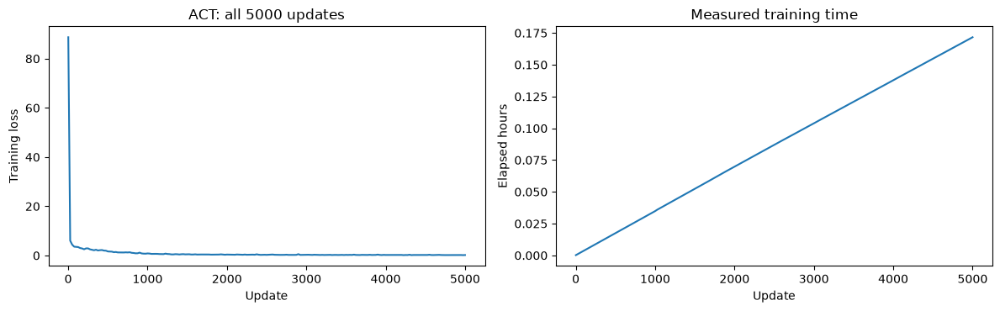

|种子|物理成功|控制步数|
|---|---|---|
|2000|False|1200|
|2001|False|1200|
|2002|True|710|
|2003|False|1200|
|2004|False|1200|
|2005|False|1200|
|2006|False|1200|
|2007|False|1200|
|2008|False|1200|
|2009|False|1200|
|2010|True|1030|
|2011|False|1200|
|2012|False|1200|
|2013|False|1200|
|2014|False|1200|
|2015|False|1200|
|2016|False|1200|
|2017|False|1200|
|2018|False|1200|
|2019|False|1200|
|2020|False|1200|
|2021|False|1200|
|2022|False|1200|
|2023|False|1200|
|2024|False|1200|
|2025|False|1200|
|2026|False|1200|
|2027|False|1200|
|2028|False|1200|
|2029|False|1200|

```json
{
  "episodes": 30,
  "physical_successes": 2,
  "seeds": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029
  ],
  "horizon": 1200,
  "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
}

```

In [31]:
import matplotlib.pyplot as plt
EVIDENCE = RUN if RUN_FULL else SNAPSHOT
metrics_file = EVIDENCE / "training-metrics.json"
if metrics_file.exists():
    metrics = json.loads(metrics_file.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot([r["step"] for r in metrics], [r["loss"] for r in metrics])
    axes[0].set(xlabel="Update", ylabel="Training loss", title="ACT: all 5000 updates")
    axes[1].plot([r["step"] for r in metrics], [r["elapsed_s"] / 3600 for r in metrics])
    axes[1].set(xlabel="Update", ylabel="Elapsed hours", title="Measured training time")
    fig.tight_layout(); display(fig); plt.close(fig)
    rows = [json.loads(s) for s in (EVIDENCE / "evaluation.jsonl").read_text().splitlines() if s.strip()]
    display(Markdown("|种子|物理成功|控制步数|\n|---|---|---|\n" + "\n".join(f"|{r['seed']}|{r['physical_success']}|{r.get('action_steps', '')}|" for r in rows)))
    display(Markdown("```json\n" + (EVIDENCE / "evaluation-summary.json").read_text() + "\n```"))
else:
    print("本次完整实验正在运行，最终曲线与30回合结果将在评估结束后保存。")


## 6. 本次成功与失败录像

预览和完整视频均来自本次正式评估；采集视频单独标注，不计入策略成功率。

本次脚本专家采集演示，种子1000；独立于学习策略评估

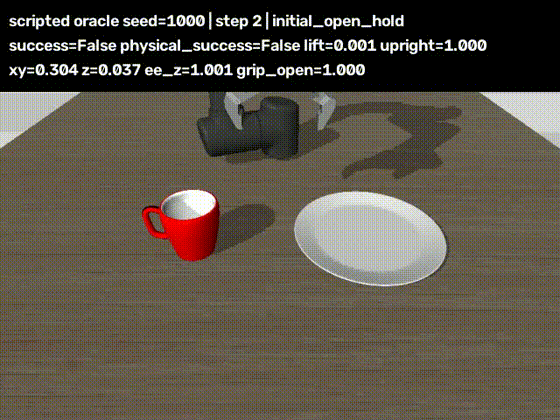

本次正式评估成功，种子2002

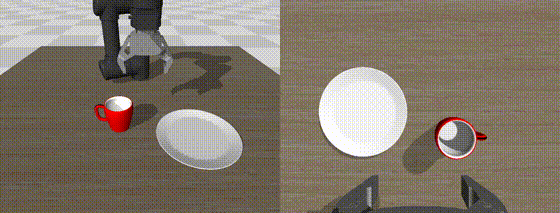

本次正式评估失败，种子2000

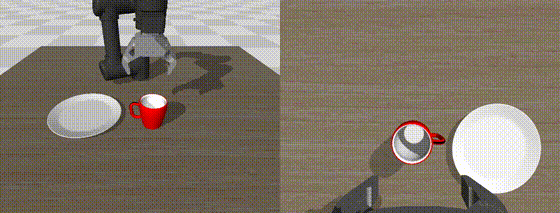

In [32]:
media_file = SNAPSHOT / "media.json"
if media_file.exists():
    for item in json.loads(media_file.read_text()):
        display(Markdown(item["label"]))
        display(Image(filename=str(SNAPSHOT / item["preview"])))
        relative = os.path.relpath(SNAPSHOT / item["video"], Path.cwd())
        display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))
else:
    print("等待本次正式评估录像；旧结果请查看抓杯子任务入口。")


## 闭环稳定性与逐步重规划诊断

首轮学习策略完整评估为2/30。随后沿用相同5000步权重，分别检查训练场景和每步重新规划，原始30回合成绩保持独立。

|独立条件|场景种子|物理成功|控制步数|
|---|---|---|---|
|原20步动作块，训练场景|1000|成功|430|
|原20步动作块，训练场景|1019|失败|1200|
|每步重规划，首轮失败场景|2000|失败|1200|
|每步重规划，首轮失败场景|2001|失败|1200|

训练场景1019中策略能够抬升杯子约0.091米，后续搬运与放置失败。训练场景闭环结果为1/2；每步重规划为0/2。这两组用于定位问题，分母分别保留。

严格完整权重加载通过；12个专家帧夹爪开闭预测全部匹配，平均关节绝对误差0.021805弧度。状态和动作归一化差异最大约5.2×10⁻⁸，两侧图像缩放一致；三条完整动作回放的末端位置观测中位误差低于0.2微米。现有证据指向学习闭环精度与稳定性需要改善，后续20号笔记本采用关闭变分隐变量、20000步和每轮刷新批次的新配方开展完整比较。

下面保留两段完整诊断失败录像及预览。四段原始录像、逐步轨迹和指纹验证记录位于原始实验归档，全部完整解码通过。


训练场景1019：抬升后搬运与放置失败

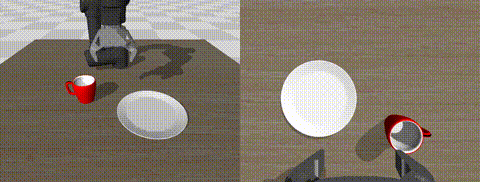

失败场景2001：每步重规划，完整1200步

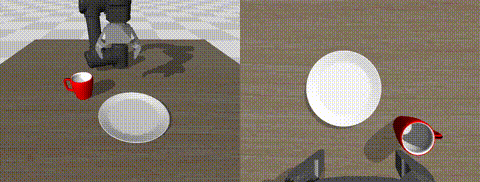

[
  {
    "file": "/data/Data14TB/01Proj/every-embodied-amd/cup-training-seeds-20261028-v1/seed1000/videos/act_full14_success_seed1000.mp4",
    "bytes": 5450092,
    "sha256": "832d7efc8107d9710067e4d53bae7e84a7aa3e11ae9fd3c6ea16d8fbcca1ee28",
    "decoded": true
  },
  {
    "file": "/data/Data14TB/01Proj/every-embodied-amd/cup-training-seeds-20261028-v1/seed1019/videos/act_full14_failure_seed1019.mp4",
    "bytes": 15991965,
    "sha256": "d9c182584cb072614b10079f130ee4ba22c7900bdead9665e9647ec69e306082",
    "decoded": true
  },
  {
    "file": "/data/Data14TB/01Proj/every-embodied-amd/cup-replan1-diagnostic-20261028-v1/seed2000/videos/act_full14_failure_seed2000.mp4",
    "bytes": 12692486,
    "sha256": "7574abd2ee41ea6bcc2dbedd936d36bdd6e33f88d0735101a8efc7cd9afffac3",
    "decoded": true
  },
  {
    "file": "/data/Data14TB/01Proj/every-embodied-amd/cup-replan1-diagnostic-20261028-v1/seed2001/videos/act_full14_failure_seed2001.mp4",
    "bytes": 4409608,
    "sha256": "4089c441

In [33]:
diagnostics = SNAPSHOT / "diagnostics"
for stem, label in [("training-scene-failure", "训练场景1019：抬升后搬运与放置失败"), ("replan1-failure", "失败场景2001：每步重规划，完整1200步")]:
    display(Markdown(label))
    display(Image(filename=str(diagnostics / (stem + ".gif"))))
    relative = os.path.relpath(diagnostics / (stem + ".mp4"), Path.cwd())
    display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))
print((diagnostics / "video-verification.json").read_text())


## 笔记本内直接播放：训练后评估录像

以下播放器保存真实完整视频数据，下载笔记本后可直接播放；原有逐回合结果、成功与失败标注仍保留在前文。视频用于观察本篇记录的策略行为，训练条件与分母以本篇结果表为准。

本篇评估录像：`success-seed2002.mp4`

In [34]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/cup-full/success-seed2002.mp4'), embed=True, width=640))


本篇评估录像：`failure-seed2000.mp4`

In [35]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/cup-full/failure-seed2000.mp4'), embed=True, width=640))
